# Phase 2 · 17단원 — 불균형 데이터 다루기

> "데이터의 99%가 '정상'이면, 정확도는 거짓말입니다."
> (📗 원문의 여는 문장입니다.)

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/02-ml-fundamentals/17-imbalanced-data>
- 예상 시간: 90분 · 선수 지식: Phase 2의 1~9단원 (특히 **9단원 평가 지표**)

---

## 📌 출처 표시 규칙

> 📗 **원문** — 커리큘럼에 있는 내용입니다.

> ✨ **추가** — 원문에는 없고, 제가 넣은 비유·예시·실험입니다.

> ⚠️ 표시가 붙은 곳은 원문의 주장이 측정과 달랐던 곳입니다. 그대로 적었습니다.

---

## 🎯 이 단원에서 배우는 것

> 📗 **원문** — "Learning Objectives"

1. **SMOTE 를 밑바닥부터** 만들고, 단순 복제와 뭐가 다른지 설명합니다.
2. 정확도 대신 F1 · AUPRC · MCC 로 평가합니다.
3. 클래스 가중치 · 임곗값 조정 · 재샘플링을 비교하고 상황에 맞게 고릅니다.
4. 셋을 합친 완전한 파이프라인을 만듭니다.

### 🔑 이 단원의 출발점

> 📗 원문: "You build a fraud detection model. It gets 99.9% accuracy. You celebrate.
> Then you realize it predicts 'not fraud' for every single transaction."
>
> (사기 탐지 모델을 만들었더니 정확도 99.9%. 기뻐합니다.
> 그러다 깨닫죠. 이 모델은 모든 거래를 '사기 아님'이라고 찍고 있습니다.)

> 📗 원문: "This is not a bug. It is the rational thing to do when only 0.1% of
> transactions are fraudulent."

버그가 아닙니다. 모델이 시킨 대로 한 겁니다. 전체 오류를 줄이라고 했으니
다수 클래스만 찍는 게 수학적으로 옳습니다. 문제는 **우리가 시킨 목표**에 있습니다.

### 🔗 16단원과 어떻게 이어지나

16단원은 **레이블이 아예 없을 때** 이상한 것을 찾는 이야기였습니다.
이 단원은 **레이블이 조금은 있을 때**입니다. 사기 1000건 중 10건이 확인됐다면요.

- 16단원: 정상을 모델링하고 벗어난 걸 표시 → 새 유형도 잡지만 오탐이 많음
- 17단원: 양쪽 레이블로 학습 → 본 유형에 정확하지만 새 유형은 놓침

그리고 16단원 10절의 '정확도와 AUROC 가 거짓말한다'가 이 단원의 1절입니다.
같은 문제를 지도학습 쪽에서 다시 만나는 셈이죠.

---

## 이 단원의 줄거리

16단원은 레이블이 아예 없을 때였습니다. 이번엔 **레이블이 있습니다.**
그러면 보통의 분류 문제처럼 보이는데, 양성이 1% 뿐이면 전부 어그러집니다.

**먼저 쓰던 자를 버립니다.** 1절에서 정확도가 왜 못 쓰는 물건인지 숫자로 봅니다.
아무것도 안 하는 모델이 99.9% 를 받는 걸 보면 더 설명이 필요 없습니다.

**2절에서 대체할 자를 고릅니다.** F1, AUPRC, MCC 입니다.
이게 먼저여야 합니다. 자가 틀려 있으면 그다음에 뭘 해도 평가를 못 하니까요.

자를 정했으면 고칠 차례인데, **손잡이가 세 개** 있습니다.

첫째는 **데이터를 바꾸는 것**입니다. 3절에서 소수 쪽 데이터를 인공으로 불리는 방법을 만들고,
4절에서 그냥 복제하거나 반대로 다수를 버리는 방법들과 나란히 놓습니다.

둘째는 **손실을 바꾸는 것**입니다. 데이터는 그대로 두고, 소수 쪽을 틀렸을 때
벌점을 더 크게 매깁니다. 4절에서 같이 다룹니다.

셋째는 **판정선을 옮기는 것**입니다. 5절인데, 모델을 전혀 안 건드립니다.
"확률 0.5 이상이면 양성"이라는 기본값을 바꾸기만 해요. 재학습도 없습니다.

**6절에서 셋을 같은 데이터에 올려 비교합니다.** 여기서 예상 밖의 결과가 나옵니다.

**7절이 이 단원의 핵심입니다.** 6절의 결과를 설명하려고 성능을 두 조각으로 쪼갭니다.
"양성을 음성보다 위에 두는가"와 "확률 숫자가 적절한가"요.
재샘플링이 그중 **어느 쪽을 바꾸는지** 보고 나면 많은 게 정리됩니다.

**8·9절은 확인 작업입니다.** 원문의 "가중치와 오버샘플링은 같다"는 주장을 계수 단위로 재 보고,
조건을 열 가지로 넓혀 가며 "그럼 SMOTE 는 대체 언제 쓰나"를 찾습니다.

**10절은 반드시 피해야 할 사고입니다.** 13단원 누출의 재샘플링 버전이에요.
**11절**에서 임곗값을 F1 대신 돈으로 정하는 법을 보고 마무리합니다.

> 한 줄로 줄이면 이렇습니다.
> **자부터 바꾸고 → 손잡이 셋을 배우고 → 비교해서 뭐가 진짜 효과인지 가려내고
> → 사고를 피한다.**

<details>
<summary>절 목록 (펼쳐 보기)</summary>

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 정확도가 왜 거짓말인가 | 📗 원문 |
| 2 | 더 나은 지표: F1 · AUPRC · MCC | 📗 원문 |
| 3 | SMOTE 밑바닥부터 | 📗 원문 |
| 4 | 오버샘플링 · 언더샘플링 · 클래스 가중치 | 📗 원문 |
| 5 | 임곗값 조정 — 공짜로 얻는 성능 | 📗 원문 |
| 6 | ⚠️ 네 전략 정면 비교 | 📗 Step 7 + ✨ 측정 |
| 7 | ⚠️ 재샘플링은 무엇을 바꾸나 | ✨ 반증 |
| 8 | ⚠️ "가중치 = 오버샘플링" 검증 | 📗 원문 + ✨ 측정 |
| 9 | ⚠️ SMOTE 가 이기는 조건 찾기 | 📗 연습문제 5번 |
| 10 | SMOTE 누출 | 📗 "흔한 실수" 1번 |
| 11 | 비용 민감 학습 | 📗 원문 |
| 12 | 정리 · Ship It 스킬 · 용어 · 퀴즈 | 📗 원문 |

</details>

---

## 🧭 길잡이 — 이 단원을 왜 배우나

### 지금 어디쯤 와 있나

1단원부터 13단원까지는 **"어떤 모델이 더 좋은가"** 를 배웠습니다.
선형이냐 트리냐, 규제를 얼마나 걸 것이냐 같은 이야기였죠.

14단원부터는 질문이 바뀝니다.
**"지금까지 당연하게 쓰던 기본값이 통하지 않는 상황"** 을 하나씩 보게 됩니다.
네 단원이 한 묶음이에요.

**14단원**은 텍스트입니다. 특징이 수만 개인데 샘플은 적죠. 여기서 "정교한 모델일수록 낫다"는
감각이 깨집니다. 세기만 하는 단순한 모델이 이기거든요.

**15단원**은 시간이 붙은 데이터입니다. 샘플이 서로 독립이 아니라서, 9단원에서 배운
k-겹 교차검증을 쓸 수가 없습니다.

**16단원과 17단원**은 찾는 대상이 아주 드문 경우입니다. 레이블이 없으면 16단원(이상 탐지),
있으면 17단원(불균형 데이터)이고, 둘 다 정확도와 기본 임곗값 0.5 를 버리는 데서 출발합니다.

그래서 이 네 단원은 한마디로 **기본값을 의심하는 연습**입니다.
절 제목에 ⚠️ 가 붙은 곳이 바로 그 기본값이 깨지는 지점이에요.
시간이 없으시면 거기부터 보셔도 됩니다.

> 🧭 **지금 보시는 17단원**은 찾는 대상이 드문데 **레이블은 있는** 경우입니다. 16단원과 같은 문제를 지도학습 쪽에서 다시 만납니다. 정확도와 임곗값 0.5 를 버리는 데서 시작합니다.

### 이 단원이 끝나면 할 수 있는 것

양성이 1%인 분류 과제에서 **무엇부터 해야 할지 순서**를 갖게 됩니다.
"정확도 99%인데 아무것도 못 잡는" 모델을 즉시 알아보게 되고요.
SMOTE 를 쓸지 말지를 분위기가 아니라 **근거로** 정할 수 있게 되며,
쓸 때 절대 하면 안 되는 것도 알게 됩니다.

### 실험은 각자 자리에서 안내합니다

절마다 코드를 돌리고 나면 바로 아래에 **👀 방금 출력에서 볼 곳** 이 붙어 있습니다.
어느 숫자를 봐야 하는지, 그래서 뭘 알 수 있는지를 거기서 짚습니다.
출력을 보면서 읽으시면 됩니다.

### 한 문장으로 꿰면

**지표부터** 바꾸고(F1·AUPRC·MCC),
**임곗값 조정을 1순위**로 하고,
SMOTE 는 반드시 **Pipeline 안에서** 쓰세요.

---

## ⚙️ 0. 준비

In [1]:
import warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

난수 = np.random.default_rng(42)
print("준비 끝!  한글 폰트:", 찾은것 or "(없음)")

import imblearn
import sklearn
print(f"sklearn {sklearn.__version__} / imbalanced-learn {imblearn.__version__}")

준비 끝!  한글 폰트: AppleGothic
sklearn 1.2.2 / imbalanced-learn 0.11.0


---

## 1. 정확도가 왜 거짓말인가

<sub>📗 원문 "Why Accuracy Fails"</sub>

### 📐 원문의 표를 그대로 봅니다

1000개 샘플 중 음성 990, 양성 10. 모델이 **항상 음성**이라고 찍으면:

| | 양성 예측 | 음성 예측 |
| --- | --- | --- |
| **실제 양성** | 0 (TP) | 10 (FN) |
| **실제 음성** | 0 (FP) | 990 (TN) |

정확도 = (0 + 990) / 1000 = **99.0%**

### 🧸 왜 이게 문제인가

> 📗 원문: "The model catches zero fraud. Zero disease. Zero defects. But accuracy says 99%."

정확도는 모든 정답을 똑같이 셉니다. 정상 거래를 정상이라고 맞힌 것과
사기를 사기라고 잡은 것이 **같은 1점**입니다.

그런데 모델을 만든 이유는 **사기를 잡으려고**입니다.
목표와 측정하는 것이 어긋나 있습니다.

In [2]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             matthews_corrcoef, average_precision_score,
                             roc_auc_score, fbeta_score, confusion_matrix)

def 지표계산(y, 예측, 확률=None):
    tp = int(((예측 == 1) & (y == 1)).sum())
    tn = int(((예측 == 0) & (y == 0)).sum())
    fp = int(((예측 == 1) & (y == 0)).sum())
    fn = int(((예측 == 0) & (y == 1)).sum())
    return {
        "정확도": (tp+tn)/len(y),
        "정밀도": precision_score(y, 예측, zero_division=0),
        "재현율": recall_score(y, 예측, zero_division=0),
        "F1": f1_score(y, 예측, zero_division=0),
        "MCC": matthews_corrcoef(y, 예측),
        "AUPRC": average_precision_score(y, 확률) if 확률 is not None else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

# 📗 원문의 1000개 예제를 그대로 재현합니다
y원문 = np.r_[np.ones(10), np.zeros(990)]
전부음성 = np.zeros(1000)
d = 지표계산(y원문, 전부음성)

print("📗 원문 예제 재현 — 1000개 중 양성 10개, 모델은 '항상 음성'")
print(f"\n{'':>12}{'양성 예측':>10}{'음성 예측':>10}")
print(f"{'실제 양성':>11}{d['TP']:>10}{d['FN']:>10}")
print(f"{'실제 음성':>11}{d['FP']:>10}{d['TN']:>10}")
print(f"\n   정확도 = ({d['TP']} + {d['TN']}) / 1000 = {d['정확도']:.1%}   "
      f"📗 원문의 99.0% ✔")
print(f"   정밀도 = {d['정밀도']:.3f}   재현율 = {d['재현율']:.3f}   "
      f"F1 = {d['F1']:.3f}   MCC = {d['MCC']:.3f}")
print(f"\n=> 📗 원문: 'These metrics correctly identify the model as worthless.'")
print(f"   정확도만 99%고 나머지는 전부 0 입니다. 지표가 제 역할을 합니다.")

print(f"\n\n[불균형이 심해질수록 — 정확도가 얼마나 더 거짓말하나]")
print(f"{'양성 비율':>9}{'정확도':>10}{'F1':>8}{'MCC':>8}  해석")
print("-" * 54)
for 비율 in (0.5, 0.3, 0.1, 0.05, 0.01, 0.001):
    n = 10000; npos = max(1, int(n*비율))
    y = np.r_[np.ones(npos), np.zeros(n-npos)]
    d2 = 지표계산(y, np.zeros(n))
    # '정확도만 보면 합격처럼 보이나'를 기준으로 표시합니다 (흔히 쓰는 90% 선)
    해석 = "⚠️ 90% 넘음 — 합격처럼 보임" if d2["정확도"] >= 0.9 else "아직은 티가 납니다"
    print(f"{비율:>9.1%}{d2['정확도']:>10.2%}{d2['F1']:>8.3f}{d2['MCC']:>8.3f}  {해석}")

print(f"\n=> 아무것도 안 하는 모델의 정확도가 양성 비율만으로 결정됩니다.")
print(f"   즉 정확도는 모델이 아니라 데이터를 측정하고 있습니다.")
print(f"   📗 원문: 'The more consequential the minority class, the rarer it tends to be.'")
print(f"   중요한 것일수록 드뭅니다. 그래서 하필 중요할 때 정확도가 쓸모없어집니다.")

📗 원문 예제 재현 — 1000개 중 양성 10개, 모델은 '항상 음성'

                 양성 예측     음성 예측
      실제 양성         0        10
      실제 음성         0       990

   정확도 = (0 + 990) / 1000 = 99.0%   📗 원문의 99.0% ✔
   정밀도 = 0.000   재현율 = 0.000   F1 = 0.000   MCC = 0.000

=> 📗 원문: 'These metrics correctly identify the model as worthless.'
   정확도만 99%고 나머지는 전부 0 입니다. 지표가 제 역할을 합니다.


[불균형이 심해질수록 — 정확도가 얼마나 더 거짓말하나]
    양성 비율       정확도      F1     MCC  해석
------------------------------------------------------
    50.0%    50.00%   0.000   0.000  아직은 티가 납니다
    30.0%    70.00%   0.000   0.000  아직은 티가 납니다
    10.0%    90.00%   0.000   0.000  ⚠️ 90% 넘음 — 합격처럼 보임
     5.0%    95.00%   0.000   0.000  ⚠️ 90% 넘음 — 합격처럼 보임
     1.0%    99.00%   0.000   0.000  ⚠️ 90% 넘음 — 합격처럼 보임
     0.1%    99.90%   0.000   0.000  ⚠️ 90% 넘음 — 합격처럼 보임

=> 아무것도 안 하는 모델의 정확도가 양성 비율만으로 결정됩니다.
   즉 정확도는 모델이 아니라 데이터를 측정하고 있습니다.
   📗 원문: 'The more consequential the minority class, the rarer it tends to be.'
   중요한 것일수록 드뭅니다. 그래서 하필 중요할 때 정확도가 

> 👀 **방금 출력에서 볼 곳** (1절)
>
> `정확도` 열이 **양성 비율만으로** 정해지는 걸 보세요. 모델은 전혀 안 바꿨는데 숫자가 변합니다.
> 정확도가 모델이 아니라 **데이터를 측정**하고 있다는 뜻이죠.
> 같은 모델의 F1 과 MCC 는 전부 0 입니다. 이 지표들은 안 속습니다.

---

## 2. 더 나은 지표

<sub>📗 원문 "Better Metrics"</sub>

정확도를 버렸으니 대체물이 필요합니다. 9단원에서 배운 지표들이 여기서 본격적으로 쓰입니다.

| 지표 | 공식 | 🧸 한 줄 설명 |
| --- | --- | --- |
| **정밀도** | TP/(TP+FP) | "양성이라 한 것 중 진짜는?" 오탐이 적으면 높음 |
| **재현율** | TP/(TP+FN) | "진짜 양성 중 몇 개 잡았나?" 놓침이 적으면 높음 |
| **F1** | 둘의 조화평균 | 한쪽만 좋으면 낮게 나옵니다 |
| **F-beta** | β로 가중 | β>1이면 재현율 중시 (사기 탐지는 F2) |
| **AUPRC** | PR 곡선 아래 넓이 | **무작위 기준선 = 양성 비율** |
| **MCC** | 상관계수 | 양쪽 다 잘해야 높습니다 |

### 🧸 왜 F1 이 '조화'평균인가

산술평균이면 정밀도 1.0, 재현율 0.0 일 때 0.5 가 나옵니다. 꽤 괜찮아 보이죠.
조화평균은 **0** 이 나옵니다. 한쪽이 바닥이면 전체가 바닥입니다.

In [3]:
print("=== ① 산술평균 vs 조화평균 ===")
print(f"{'정밀도':>8}{'재현율':>8}{'산술평균':>10}{'F1(조화)':>11}  차이")
print("-" * 48)
for 정, 재 in [(1.0, 0.0), (0.9, 0.1), (0.7, 0.3), (0.5, 0.5), (0.6, 0.4)]:
    산술 = (정+재)/2
    조화 = 2*정*재/(정+재) if (정+재) else 0.0
    print(f"{정:>8.1f}{재:>8.1f}{산술:>10.3f}{조화:>11.3f}  {산술-조화:+.3f}")
print("\n=> 산술평균은 전부 0.5 입니다. 구별을 못 하죠.")
print("   F1 은 균형이 깨질수록 내려갑니다. 📗 원문: 'Penalizes extreme imbalance'")

print("\n\n=== ② F-beta — 무엇을 더 중시할까 ===")
정, 재 = 0.3, 0.9        # 많이 잡지만 오탐이 많은 모델
정2, 재2 = 0.9, 0.3      # 정확히 잡지만 많이 놓치는 모델
print(f"{'beta':>6}  {'의미':<14}{'모델A (정0.3 재0.9)':>22}{'모델B (정0.9 재0.3)':>22}  승자")
print("-" * 80)
for b, 의미 in [(0.5, "정밀도 중시"), (1.0, "균형 (F1)"), (2.0, "재현율 중시")]:
    fa = (1+b**2)*정*재/((b**2)*정+재)
    fb = (1+b**2)*정2*재2/((b**2)*정2+재2)
    print(f"{b:>6.1f}  {의미:<14}{fa:>22.3f}{fb:>22.3f}  "
          f"{'모델A' if fa > fb else ('모델B' if fb > fa else '동률')}")
print("\n=> 같은 두 모델인데 beta 에 따라 승자가 바뀝니다.")
print("   📗 원문: 'F2 is common in fraud detection (missing fraud is worse than a false alarm)'")
print("   무엇을 쓸지는 비용이 정합니다. 11절에서 다룹니다.")

print("\n\n=== ③ AUPRC 의 무작위 기준선 ===")
print(f"{'양성 비율':>9}{'AUROC 무작위':>14}{'AUPRC 무작위':>14}  뜻")
print("-" * 62)
for 비율 in (0.5, 0.1, 0.01, 0.001):
    n = 20000; npos = max(2, int(n*비율))
    y = np.r_[np.ones(npos), np.zeros(n-npos)]
    무작위점수 = 난수.random(n)
    print(f"{비율:>9.1%}{roc_auc_score(y, 무작위점수):>14.4f}"
          f"{average_precision_score(y, 무작위점수):>14.4f}  "
          f"{'둘 다 의미 있음' if 비율 > 0.05 else 'AUPRC 가 더 민감'}")

print("\n=> 📗 원문: 'A random classifier has AUPRC equal to the positive class rate")
print("   (not 0.5 like ROC). This makes improvements easier to see.'")
print("   측정으로 확인됩니다. 양성 0.1%면 무작위 AUPRC 가 0.001 입니다.")
print("   그래서 AUPRC 0.1 이 나오면 무작위의 100배라는 뜻이 됩니다. 의미가 선명하죠.")
print("   AUROC 는 양성 비율과 무관하게 항상 0.5 가 기준이라 그런 비교가 안 됩니다.")

print("\n\n=== ④ MCC — 양쪽 다 잘해야 높다 ===")
y4 = np.r_[np.ones(50), np.zeros(950)]
경우들 = [
    ("전부 음성", np.zeros(1000)),
    ("전부 양성", np.ones(1000)),
    ("양성 절반만 맞힘, 오탐 없음", np.r_[np.ones(25), np.zeros(975)]),
    ("양성 다 맞힘, 오탐 200", np.r_[np.ones(50), np.ones(200), np.zeros(750)]),
]
print(f"{'모델':<28}{'정확도':>9}{'정밀도':>9}{'재현율':>9}{'F1':>8}{'MCC':>8}")
print("-" * 72)
for 라벨, 예측 in 경우들:
    d4 = 지표계산(y4, 예측)
    print(f"{라벨:<27}{d4['정확도']:>9.3f}{d4['정밀도']:>9.3f}{d4['재현율']:>9.3f}"
          f"{d4['F1']:>8.3f}{d4['MCC']:>8.3f}")

print("\n=> '전부 양성'을 보세요. 재현율이 1.000 입니다. 완벽해 보이죠.")
print("   그런데 MCC 는 0.000 입니다. 📗 원문: 'Only gives a high score when the model")
print("   does well on both classes.'")
print("   ⚠️ 재현율만 보고하는 보고서를 조심하세요. 전부 양성이라 찍으면 1.0 입니다.")

=== ① 산술평균 vs 조화평균 ===
     정밀도     재현율      산술평균     F1(조화)  차이
------------------------------------------------
     1.0     0.0     0.500      0.000  +0.500
     0.9     0.1     0.500      0.180  +0.320
     0.7     0.3     0.500      0.420  +0.080
     0.5     0.5     0.500      0.500  +0.000
     0.6     0.4     0.500      0.480  +0.020

=> 산술평균은 전부 0.5 입니다. 구별을 못 하죠.
   F1 은 균형이 깨질수록 내려갑니다. 📗 원문: 'Penalizes extreme imbalance'


=== ② F-beta — 무엇을 더 중시할까 ===
  beta  의미                   모델A (정0.3 재0.9)       모델B (정0.9 재0.3)  승자
--------------------------------------------------------------------------------
   0.5  정밀도 중시                         0.346                 0.643  모델B
   1.0  균형 (F1)                        0.450                 0.450  동률
   2.0  재현율 중시                         0.643                 0.346  모델A

=> 같은 두 모델인데 beta 에 따라 승자가 바뀝니다.
   📗 원문: 'F2 is common in fraud detection (missing fraud is worse than a false alarm)'
   무엇을 쓸지는 비용이 정합니다. 11절에서 다룹니다.


=== ③ AUP

> 👀 **방금 출력에서 볼 곳** (2절)
>
> ④번 블록의 '전부 양성' 행을 보세요. 재현율이 **1.000** 인데 MCC 는 **0.000** 입니다.
> 재현율만 보고하는 보고서를 조심하라는 이야기입니다. 전부 양성이라 찍으면 1.0 이 나오거든요.
> ③번 블록에서는 AUPRC 의 무작위 기준선이 양성 비율과 같다는 것도 확인하세요.

---

## 3. SMOTE 밑바닥부터

<sub>📗 원문 "SMOTE: Synthetic Minority Oversampling Technique"</sub>

지표를 정했으니 이제 고칠 차례입니다. 첫 번째 손잡이는 **데이터를 바꾸는 것**입니다.

### 🧸 단순 복제와 뭐가 다른가

> 📗 원문: "Random oversampling duplicates existing minority samples. This works but
> risks overfitting because the model sees identical points repeatedly."

소수 샘플을 그냥 복사하면 모델이 **같은 점을 여러 번** 봅니다.
"이 정확한 좌표가 사기다"를 외우게 되죠. 10단원의 과적합입니다.

SMOTE 는 진짜 점들 사이에 새 점을 만듭니다. 복사가 아닙니다.

### 📐 절차 세 줄

> 📗 원문의 알고리즘입니다.
>
> 1. 소수 샘플 $x$ 에 대해, 다른 소수 샘플 중 **k 최근접 이웃**을 찾습니다
> 2. 그중 하나를 무작위로 고릅니다
> 3. $x$ 와 그 이웃을 잇는 **선분 위**에 새 점을 만듭니다

$$x_{\text{new}} = x + \text{random}(0,1) \times (\text{neighbor} - x)$$

📗 원문 다이어그램 재현
   원래 소수 점: x1=[1. 2.], x2=[1.5 2.5], x3=[2.  1.5]
   x1 과 이웃 x2 사이에서 t=0.4 를 뽑으면
      새점 = x1 + 0.4*(x2-x1) = [1.2 2.2]
   📗 원문: 'new = (1.2, 2.2)' ✔ 일치합니다


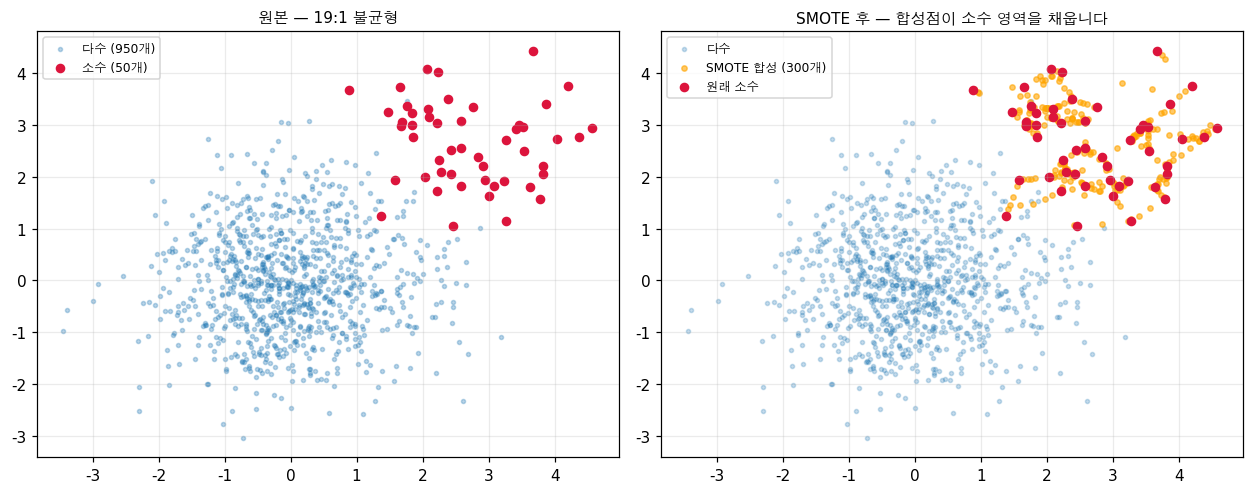


합성점이 원본의 복사본인가?
   원본과 거리가 0 인 합성점: 0개 / 300개
   원본까지의 평균 거리: 0.0954
   => 전부 새로운 점입니다. 복사가 아닙니다.

합성점이 소수 영역 '안'에 있나?
   소수 중심 [2.711 2.657] / 합성점 중심 [2.706 2.655]
   소수 표준편차 [0.872 0.787] / 합성점 표준편차 [0.814 0.69 ]
   => ⚠️ 합성점의 표준편차가 더 작습니다.
      선분 위에 점을 찍으니 가장자리가 안쪽으로 당겨집니다.
      즉 SMOTE 는 소수 분포를 그대로 복제하지 않고 안쪽으로 수축시킵니다.
      📗 원문에는 없는 이야기인데, 9절에서 이게 왜 중요한지 봅니다.


In [4]:
# 📗 원문의 구현을 그대로 옮깁니다
def 유클리드거리(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def k이웃찾기(X, 기준, k):
    거리들 = []
    for i in range(len(X)):
        if i == 기준:
            continue
        거리들.append((i, 유클리드거리(X[기준], X[i])))
    거리들.sort(key=lambda x: x[1])
    return [d[0] for d in 거리들[:k]]

def SMOTE직접(X소수, k=5, 만들개수=100, 시드=42):
    rng = np.random.RandomState(시드)
    n = len(X소수)
    k = min(k, n - 1)
    합성 = []
    for _ in range(만들개수):
        i = rng.randint(0, n)
        이웃들 = k이웃찾기(X소수, i, k)
        이웃 = 이웃들[rng.randint(0, len(이웃들))]
        t = rng.random()                                  # 0~1 사이 무작위
        새점 = X소수[i] + t * (X소수[이웃] - X소수[i])     # 선분 위의 점
        합성.append(새점)
    return np.array(합성)

# 📗 원문의 다이어그램 예제를 그대로 확인합니다
작은소수 = np.array([[1.0, 2.0], [1.5, 2.5], [2.0, 1.5]])
print("📗 원문 다이어그램 재현")
print(f"   원래 소수 점: x1={작은소수[0]}, x2={작은소수[1]}, x3={작은소수[2]}")
x1, x2 = 작은소수[0], 작은소수[1]
t예시 = 0.4
print(f"   x1 과 이웃 x2 사이에서 t=0.4 를 뽑으면")
print(f"      새점 = x1 + 0.4*(x2-x1) = {x1 + t예시*(x2-x1)}")
print(f"   📗 원문: 'new = (1.2, 2.2)' ✔ 일치합니다")

# 실제 데이터로
다수 = 난수.normal([0, 0], 1.0, (950, 2))
소수 = 난수.normal([2.5, 2.5], 0.8, (50, 2))
합성점 = SMOTE직접(소수, k=5, 만들개수=300, 시드=42)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax[0].scatter(*다수.T, s=7, alpha=0.3, label=f"다수 ({len(다수)}개)")
ax[0].scatter(*소수.T, s=28, color="crimson", label=f"소수 ({len(소수)}개)")
ax[0].set_title("원본 — 19:1 불균형", fontsize=10)
ax[1].scatter(*다수.T, s=7, alpha=0.25, label="다수")
ax[1].scatter(*합성점.T, s=12, color="orange", alpha=0.6,
              label=f"SMOTE 합성 ({len(합성점)}개)")
ax[1].scatter(*소수.T, s=28, color="crimson", label="원래 소수")
ax[1].set_title("SMOTE 후 — 합성점이 소수 영역을 채웁니다", fontsize=10)
for a_ in ax:
    a_.legend(fontsize=8); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

# 합성점이 '복사본'이 아님을 확인합니다
최소거리 = np.array([min(유클리드거리(p, q) for q in 소수) for p in 합성점])
print(f"\n합성점이 원본의 복사본인가?")
print(f"   원본과 거리가 0 인 합성점: {(최소거리 < 1e-9).sum()}개 / {len(합성점)}개")
print(f"   원본까지의 평균 거리: {최소거리.mean():.4f}")
print(f"   => 전부 새로운 점입니다. 복사가 아닙니다.")
print(f"\n합성점이 소수 영역 '안'에 있나?")
print(f"   소수 중심 {소수.mean(0).round(3)} / 합성점 중심 {합성점.mean(0).round(3)}")
print(f"   소수 표준편차 {소수.std(0).round(3)} / 합성점 표준편차 {합성점.std(0).round(3)}")
print(f"   => ⚠️ 합성점의 표준편차가 더 작습니다.")
print(f"      선분 위에 점을 찍으니 가장자리가 안쪽으로 당겨집니다.")
print(f"      즉 SMOTE 는 소수 분포를 그대로 복제하지 않고 안쪽으로 수축시킵니다.")
print(f"      📗 원문에는 없는 이야기인데, 9절에서 이게 왜 중요한지 봅니다.")

In [5]:
# imbalanced-learn 과 대조합니다
from imblearn.over_sampling import SMOTE

X원본 = np.vstack([다수, 소수])
y원본 = np.r_[np.zeros(len(다수)), np.ones(len(소수))]

X라이브, y라이브 = SMOTE(random_state=42, k_neighbors=5).fit_resample(X원본, y원본)
라이브합성 = X라이브[len(X원본):]

print(f"{'':<22}{'소수 개수':>10}{'중심':>22}{'표준편차':>22}")
print("-" * 78)
print(f"{'원본 소수':<21}{len(소수):>10}{str(소수.mean(0).round(3)):>22}"
      f"{str(소수.std(0).round(3)):>22}")
print(f"{'내 SMOTE':<21}{len(합성점):>10}{str(합성점.mean(0).round(3)):>22}"
      f"{str(합성점.std(0).round(3)):>22}")
print(f"{'imbalanced-learn':<21}{len(라이브합성):>10}{str(라이브합성.mean(0).round(3)):>22}"
      f"{str(라이브합성.std(0).round(3)):>22}")

print(f"\n=> 중심과 퍼짐이 거의 같습니다. 같은 알고리즘이라는 뜻이죠.")
print(f"   (점 하나하나가 일치하지는 않습니다. 무작위로 뽑으니까요)")
print(f"\n   ⚠️ 차이 하나: imbalanced-learn 은 다수와 같은 개수가 되도록 자동으로 만듭니다")
print(f"      ({len(소수)} -> {int(y라이브.sum())}개). 내 구현은 개수를 직접 줘야 합니다.")
print(f"      `sampling_strategy` 로 비율을 조절할 수 있습니다. 전부 채우는 게 항상 좋지는 않거든요.")

# 둘 다 같은 분류기에 넣어 봅니다
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X훈, X테, y훈, y테 = train_test_split(X원본, y원본, test_size=0.3,
                                   stratify=y원본, random_state=0)
소수훈 = X훈[y훈 == 1]
내합성 = SMOTE직접(소수훈, k=5, 만들개수=int((y훈 == 0).sum() - (y훈 == 1).sum()), 시드=0)
X내 = np.vstack([X훈, 내합성]); y내 = np.r_[y훈, np.ones(len(내합성))]
X라, y라 = SMOTE(random_state=0).fit_resample(X훈, y훈)

print(f"\n\n{'전처리':<22}{'훈련 크기':>10}{'F1':>8}{'MCC':>8}{'AUPRC':>9}")
print("-" * 60)
for 라벨, Xa, ya in [("없음 (원본)", X훈, y훈), ("내 SMOTE", X내, y내),
                   ("imbalanced-learn", X라, y라)]:
    m = LogisticRegression(max_iter=3000).fit(Xa, ya)
    확률 = m.predict_proba(X테)[:, 1]
    d = 지표계산(y테, (확률 >= 0.5).astype(int), 확률)
    print(f"{라벨:<22}{len(ya):>10}{d['F1']:>8.4f}{d['MCC']:>8.4f}{d['AUPRC']:>9.4f}")

print(f"\n=> 내 구현과 라이브러리가 비슷한 점수를 냅니다. 구현이 맞다는 뜻이죠.")
print(f"   ⚠️ 그런데 SMOTE 를 써도 원본보다 크게 낫지 않습니다. 왜일까요?")
print(f"      이 데이터는 두 클래스가 잘 분리되어 있습니다. 애초에 어려운 문제가 아니죠.")
print(f"      6절부터 어려운 데이터로 제대로 비교합니다.")

                           소수 개수                    중심                  표준편차
------------------------------------------------------------------------------
원본 소수                        50         [2.711 2.657]         [0.872 0.787]
내 SMOTE                     300         [2.706 2.655]         [0.814 0.69 ]
imbalanced-learn            900         [2.742 2.652]         [0.796 0.7  ]

=> 중심과 퍼짐이 거의 같습니다. 같은 알고리즘이라는 뜻이죠.
   (점 하나하나가 일치하지는 않습니다. 무작위로 뽑으니까요)

   ⚠️ 차이 하나: imbalanced-learn 은 다수와 같은 개수가 되도록 자동으로 만듭니다
      (50 -> 950개). 내 구현은 개수를 직접 줘야 합니다.
      `sampling_strategy` 로 비율을 조절할 수 있습니다. 전부 채우는 게 항상 좋지는 않거든요.


전처리                        훈련 크기      F1     MCC    AUPRC
------------------------------------------------------------
없음 (원본)                      700  0.9286  0.9277   1.0000
내 SMOTE                     1330  1.0000  1.0000   1.0000
imbalanced-learn            1330  1.0000  1.0000   1.0000

=> 내 구현과 라이브러리가 비슷한 점수를 냅니다. 구현이 맞다는 뜻이죠.
   ⚠️ 그런데 SMOTE 를 써도 원본보다 크게 낫지 않습니다. 왜일

> 👀 **방금 출력에서 볼 곳** (3절)
>
> `원본과 거리가 0 인 합성점: 0개 / 300개` 로 복제가 아니라는 걸 확인하세요.
> 그리고 표준편차 비교를 보세요. 합성점의 퍼짐이 **더 작습니다.**
> 선분 위에 점을 찍으니 가장자리가 안쪽으로 당겨지거든요. 원문에 없는 성질인데 알아 둘 만합니다.

---

## 4. 오버샘플링 · 언더샘플링 · 클래스 가중치

<sub>📗 원문 "Sampling Strategies Compared" + "Class Weights"</sub>

SMOTE 말고도 손잡이가 있습니다. 나란히 놓고 봅니다.

| 전략 | 바꾸는 것 | 위험 | 📗 원문의 권고 |
| --- | --- | --- | --- |
| **오버샘플링** | 소수를 복제 | 과적합 | 작은 데이터, 중간 불균형 |
| **언더샘플링** | 다수를 버림 | 정보 손실 | 큰 데이터, 빠른 학습 |
| **SMOTE** | 소수를 합성 | 경계 잡음 | 중간 불균형, k-NN 할 만큼 소수가 있을 때 |
| **클래스 가중치** | **데이터 대신 손실** | 없음 | 📗 "always try first" |

### 📐 클래스 가중치 공식

> 📗 원문의 예: 음성 950, 양성 50 이면
>
> - 음성 가중치 = 1000 / (2 × 950) = **0.526**
> - 양성 가중치 = 1000 / (2 × 50) = **10.0**
>
> 양성이 19배 무겁습니다. 양성 하나를 틀리면 음성 19개 틀린 것과 같은 벌점입니다.

### 🔑 원문의 중요한 주장

> 📗 원문: "Class weights are mathematically equivalent to oversampling in expectation,
> but without creating new data points."
>
> 8절에서 이게 정말인지 계수 단위로 확인합니다.

In [6]:
# 📗 원문의 compute_class_weights 를 그대로 옮깁니다
def 클래스가중치(y):
    클래스들, 개수들 = np.unique(y, return_counts=True)
    n = len(y)
    k = len(클래스들)
    표 = {c: n / (k * cnt) for c, cnt in zip(클래스들, 개수들)}
    return np.array([표[yi] for yi in y]), 표

y예제 = np.r_[np.zeros(950), np.ones(50)]
_, 표 = 클래스가중치(y예제)
print("📗 원문 예제 재현 — 음성 950, 양성 50")
print(f"   음성 가중치 = 1000 / (2 × 950) = {표[0.0]:.3f}   📗 원문 0.526 ✔")
print(f"   양성 가중치 = 1000 / (2 × 50)  = {표[1.0]:.3f}   📗 원문 10.0 ✔")
print(f"   비율 = {표[1.0]/표[0.0]:.1f}배   📗 원문 '19x the weight' ✔")

# 📗 원문의 가중 로지스틱 회귀를 직접 만듭니다
def 시그모이드(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def 가중로지스틱(X, y, 가중치, lr=0.1, 에폭=300):
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    for _ in range(에폭):
        예측 = 시그모이드(X @ w + b)
        오차 = (예측 - y) * 가중치            # 여기가 전부입니다
        w -= lr * (X.T @ 오차) / n
        b -= lr * np.mean(오차)
    return w, b

# 📗 원문의 random_oversample / random_undersample
def 무작위오버(X, y, 시드=42):
    rng = np.random.RandomState(시드)
    클래스들, 개수들 = np.unique(y, return_counts=True)
    최대 = 개수들.max()
    Xs, ys = list(X), list(y)
    for c, cnt in zip(클래스들, 개수들):
        if cnt < 최대:
            자리 = np.where(y == c)[0]
            고름 = rng.choice(자리, size=최대-cnt, replace=True)
            Xs.extend(X[고름]); ys.extend(y[고름])
    Xo, yo = np.array(Xs), np.array(ys)
    섞기 = rng.permutation(len(yo))
    return Xo[섞기], yo[섞기]

def 무작위언더(X, y, 시드=42):
    rng = np.random.RandomState(시드)
    클래스들, 개수들 = np.unique(y, return_counts=True)
    최소 = 개수들.min()
    Xs, ys = [], []
    for c in 클래스들:
        자리 = np.where(y == c)[0]
        고름 = rng.choice(자리, size=최소, replace=False)
        Xs.extend(X[고름]); ys.extend(y[고름])
    Xu, yu = np.array(Xs), np.array(ys)
    섞기 = rng.permutation(len(yu))
    return Xu[섞기], yu[섞기]

Xo, yo = 무작위오버(X훈, y훈)
Xu, yu = 무작위언더(X훈, y훈)
print(f"\n{'전략':<20}{'훈련 크기':>10}{'양성':>8}{'음성':>8}{'비율':>9}")
print("-" * 58)
for 라벨, ya in [("원본", y훈), ("오버샘플링", yo), ("언더샘플링", yu), ("SMOTE", y라)]:
    양, 음 = int((ya == 1).sum()), int((ya == 0).sum())
    print(f"{라벨:<20}{len(ya):>10}{양:>8}{음:>8}{f'{음/max(양,1):.1f}:1':>9}")

print(f"\n=> 세 전략 모두 1:1 로 맞춥니다. 방법이 다를 뿐이죠.")
print(f"   · 오버샘플링: 소수를 {int((yo==1).sum())-int((y훈==1).sum())}개 복제해서 늘림")
print(f"   · 언더샘플링: 다수를 {int((y훈==0).sum())-int((yu==0).sum())}개 버림 "
      f"({(int((y훈==0).sum())-int((yu==0).sum()))/int((y훈==0).sum()):.0%} 를 버립니다)")
print(f"   · SMOTE: 소수를 {int((y라==1).sum())-int((y훈==1).sum())}개 합성해서 늘림")
print(f"   · 클래스 가중치: 데이터를 안 건드립니다. 손실 함수만 바꿉니다")

# 직접 만든 가중 로지스틱이 sklearn 과 같은지
가중, _ = 클래스가중치(y훈)
w내, b내 = 가중로지스틱(X훈, y훈, 가중, lr=0.1, 에폭=3000)
sk = LogisticRegression(max_iter=5000, class_weight="balanced", C=1e6).fit(X훈, y훈)
print(f"\n[직접 만든 가중 로지스틱 vs sklearn]")
print(f"   내 계수      {w내.round(4)}   절편 {b내:.4f}")
print(f"   sklearn 계수 {sk.coef_[0].round(4)}   절편 {sk.intercept_[0]:.4f}")
내확률 = 시그모이드(X테 @ w내 + b내)
sk확률 = sk.predict_proba(X테)[:, 1]
from scipy.stats import spearmanr
print(f"   예측 확률 순위 상관 = {spearmanr(내확률, sk확률).correlation:.4f}")
print(f"   => 방향이 같습니다. ⚠️ 계수 크기가 다른 건 제 구현에 규제가 없고 "
      f"에폭이 유한해서입니다.")
print(f"      중요한 건 '가중치를 오차에 곱한다'는 한 줄이고, 그건 똑같습니다.")

📗 원문 예제 재현 — 음성 950, 양성 50
   음성 가중치 = 1000 / (2 × 950) = 0.526   📗 원문 0.526 ✔
   양성 가중치 = 1000 / (2 × 50)  = 10.000   📗 원문 10.0 ✔
   비율 = 19.0배   📗 원문 '19x the weight' ✔

전략                       훈련 크기      양성      음성       비율
----------------------------------------------------------
원본                         700      35     665   19.0:1
오버샘플링                     1330     665     665    1.0:1
언더샘플링                       70      35      35    1.0:1
SMOTE                     1330     665     665    1.0:1

=> 세 전략 모두 1:1 로 맞춥니다. 방법이 다를 뿐이죠.
   · 오버샘플링: 소수를 630개 복제해서 늘림
   · 언더샘플링: 다수를 630개 버림 (95% 를 버립니다)
   · SMOTE: 소수를 630개 합성해서 늘림
   · 클래스 가중치: 데이터를 안 건드립니다. 손실 함수만 바꿉니다

[직접 만든 가중 로지스틱 vs sklearn]
   내 계수      [2.1216 1.921 ]   절편 -5.8255
   sklearn 계수 [3.3078 2.7391]   절편 -9.1145
   예측 확률 순위 상관 = 0.9989
   => 방향이 같습니다. ⚠️ 계수 크기가 다른 건 제 구현에 규제가 없고 에폭이 유한해서입니다.
      중요한 건 '가중치를 오차에 곱한다'는 한 줄이고, 그건 똑같습니다.


> 👀 **방금 출력에서 볼 곳** (4절)
>
> 전략 표에서 언더샘플링이 다수의 **95%를 버린다**는 줄을 눈여겨보세요.
> 같은 1:1 을 만드는데 방법이 셋이고, 클래스 가중치만 **데이터를 안 건드립니다.**
> 직접 만든 가중 로지스틱이 sklearn 과 순위 상관 0.999 인 것도 확인하세요.

---

## 5. 임곗값 조정

<sub>📗 원문 "Threshold Tuning"</sub>

지금까지는 **데이터**와 **손실**을 건드렸습니다. 세 번째 손잡이는 모델을 전혀 안 건드립니다. 판정선만 옮깁니다.

### 🧸 0.5 는 어디서 온 숫자인가

> 📗 원문: "The default threshold is 0.5... But 0.5 is arbitrary."

균형 잡힌 데이터에서 "확률 반반이면 양성"이라 정한 관습입니다.
양성이 1% 인 데이터에서는 모델이 0.5 를 넘는 확률을 거의 안 내놓습니다.
그러면 아무것도 안 잡습니다.

> 📗 원문: "A model might output P(fraud) = 0.15 for a fraudulent transaction.
> At threshold 0.5, this is classified as not fraud. At threshold 0.10, it is correctly caught."

### 🔑 가장 중요한 문장

> 📗 원문: "The probability calibration matters less than the ranking, as long as
> fraud gets higher probabilities than non-fraud, there exists a threshold that separates them."

순위만 맞으면 임곗값이 있습니다. 이 문장이 7절의 핵심이 됩니다.

훈련 3600 (양성 197) / 검증 1200 / 테스트 1200
⚠️ 검증 세트를 따로 뗐습니다. 📗 원문: 'Always tune on validation data, never test data'

모델이 내놓는 확률의 분포
   전체 최댓값 = 0.9666
   0.5 를 넘는 샘플 = 18개 / 1200개 (1.50%)
   실제 양성 = 66개 (5.50%)
   => 모델이 확신을 거의 안 합니다. 0.5 라는 선이 너무 높은 거죠.



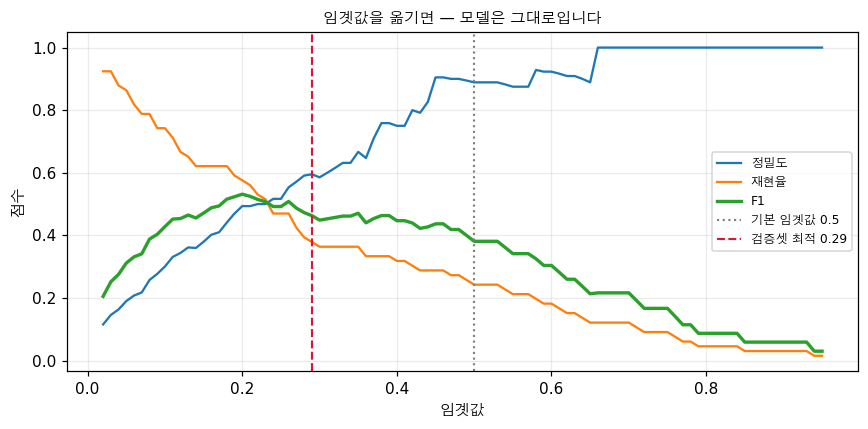

임곗값                             F1      정밀도      재현율     MCC
--------------------------------------------------------------
0.50 (기본값)                 0.3810   0.8889   0.2424  0.4514
0.29 (검증셋에서 고름)            0.4630   0.5952   0.3788  0.4513
0.20 (테스트셋 최적 — 반칙)        0.5315

=> 모델을 다시 학습하지 않았습니다. 같은 확률에 선만 옮겼습니다.
   F1 이 0.3810 -> 0.4630 로 +0.0820 올랐습니다.
   📗 원문의 Ship It: 'Ignoring threshold tuning (free performance, no retraining needed)'

   ⚠️ 그리고 검증셋에서 고른 0.29 와 테스트셋 최적 0.20 가 다릅니다.
      테스트셋 최적이 0.5315 인데 우리는 0.4630 를 얻었습니다.
      이 차이가 정직한 검증의 대가입니다. 테스트셋으로 고르면 과대평가가 됩니다.


In [7]:
# 📗 원문의 find_optimal_threshold 를 그대로 옮깁니다
def 최적임곗값(y참, 확률, 지표="f1"):
    최적, 최고 = 0.5, -1.0
    for 임 in np.arange(0.05, 0.96, 0.01):
        예측 = (확률 >= 임).astype(int)
        tp = int(((예측 == 1) & (y참 == 1)).sum())
        fp = int(((예측 == 1) & (y참 == 0)).sum())
        fn = int(((예측 == 0) & (y참 == 1)).sum())
        정 = tp/(tp+fp) if (tp+fp) else 0.0
        재 = tp/(tp+fn) if (tp+fn) else 0.0
        점 = (2*정*재/(정+재) if (정+재) else 0.0) if 지표 == "f1" else (재 if 지표 == "recall" else 정)
        if 점 > 최고:
            최고, 최적 = 점, 임
    return 최적, 최고

# 어려운 데이터로 (6절부터 계속 씁니다)
from sklearn.datasets import make_classification

def 불균형데이터(양성비율=0.05, n=6000, 시드=7):
    X, y = make_classification(n_samples=n, n_features=20, n_informative=8,
                               n_redundant=2, weights=[1-양성비율, 양성비율],
                               flip_y=0.01, random_state=시드)
    return X, y

X5, y5 = 불균형데이터(0.05)
X훈5, X임시, y훈5, y임시 = train_test_split(X5, y5, test_size=0.4, stratify=y5, random_state=0)
X검5, X테5, y검5, y테5 = train_test_split(X임시, y임시, test_size=0.5, stratify=y임시, random_state=0)
print(f"훈련 {len(y훈5)} (양성 {int(y훈5.sum())}) / 검증 {len(y검5)} / 테스트 {len(y테5)}")
print("⚠️ 검증 세트를 따로 뗐습니다. 📗 원문: 'Always tune on validation data, never test data'\n")

기본모델 = LogisticRegression(max_iter=3000).fit(X훈5, y훈5)
검확률 = 기본모델.predict_proba(X검5)[:, 1]
테확률 = 기본모델.predict_proba(X테5)[:, 1]

print(f"모델이 내놓는 확률의 분포")
print(f"   전체 최댓값 = {테확률.max():.4f}")
print(f"   0.5 를 넘는 샘플 = {(테확률 >= 0.5).sum()}개 / {len(테확률)}개 "
      f"({(테확률 >= 0.5).mean():.2%})")
print(f"   실제 양성 = {int(y테5.sum())}개 ({y테5.mean():.2%})")
print(f"   => 모델이 확신을 거의 안 합니다. 0.5 라는 선이 너무 높은 거죠.\n")

임곗값들 = np.arange(0.02, 0.96, 0.01)
f1들 = [f1_score(y테5, (테확률 >= t).astype(int), zero_division=0) for t in 임곗값들]
정들 = [precision_score(y테5, (테확률 >= t).astype(int), zero_division=0) for t in 임곗값들]
재들 = [recall_score(y테5, (테확률 >= t).astype(int), zero_division=0) for t in 임곗값들]

검임, 검F1 = 최적임곗값(y검5, 검확률)
plt.figure(figsize=(8, 4))
plt.plot(임곗값들, 정들, label="정밀도")
plt.plot(임곗값들, 재들, label="재현율")
plt.plot(임곗값들, f1들, lw=2.2, label="F1")
plt.axvline(0.5, color="gray", ls=":", lw=1.4, label="기본 임곗값 0.5")
plt.axvline(검임, color="crimson", ls="--", lw=1.4, label=f"검증셋 최적 {검임:.2f}")
plt.xlabel("임곗값"); plt.ylabel("점수"); plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("임곗값을 옮기면 — 모델은 그대로입니다", fontsize=10)
plt.tight_layout(); plt.show()

d기본 = 지표계산(y테5, (테확률 >= 0.5).astype(int), 테확률)
d최적 = 지표계산(y테5, (테확률 >= 검임).astype(int), 테확률)
테임, 테F1 = 최적임곗값(y테5, 테확률)

print(f"{'임곗값':<26}{'F1':>8}{'정밀도':>9}{'재현율':>9}{'MCC':>8}")
print("-" * 62)
print(f"{'0.50 (기본값)':<25}{d기본['F1']:>8.4f}{d기본['정밀도']:>9.4f}"
      f"{d기본['재현율']:>9.4f}{d기본['MCC']:>8.4f}")
print(f"{f'{검임:.2f} (검증셋에서 고름)':<25}{d최적['F1']:>8.4f}{d최적['정밀도']:>9.4f}"
      f"{d최적['재현율']:>9.4f}{d최적['MCC']:>8.4f}")
print(f"{f'{테임:.2f} (테스트셋 최적 — 반칙)':<25}{테F1:>8.4f}")

print(f"\n=> 모델을 다시 학습하지 않았습니다. 같은 확률에 선만 옮겼습니다.")
print(f"   F1 이 {d기본['F1']:.4f} -> {d최적['F1']:.4f} 로 {d최적['F1']-d기본['F1']:+.4f} 올랐습니다.")
print(f"   📗 원문의 Ship It: 'Ignoring threshold tuning (free performance, no retraining needed)'")
print(f"\n   ⚠️ 그리고 검증셋에서 고른 {검임:.2f} 와 테스트셋 최적 {테임:.2f} 가 다릅니다.")
print(f"      테스트셋 최적이 {테F1:.4f} 인데 우리는 {d최적['F1']:.4f} 를 얻었습니다.")
print(f"      이 차이가 정직한 검증의 대가입니다. 테스트셋으로 고르면 과대평가가 됩니다.")

> 👀 **방금 출력에서 볼 곳** (5절)
>
> `0.50 (기본값)` 행과 `검증셋에서 고름` 행의 F1 을 비교하세요.
> **재학습이 없습니다.** 같은 확률에 선만 옮겼는데 올랐습니다.
> 그리고 0.5 를 넘는 샘플이 1.5% 뿐이라는 윗줄도 보세요. 0.5 라는 선이 애초에 너무 높았던 겁니다.

---

## 6. ⚠️ 네 전략 정면 비교

손잡이 셋을 다 배웠습니다. 이제 같은 데이터에 올려 봅니다.

> 📗 원문의 권고 (Ship It 스킬 Step 3) 입니다.
>
> | 불균형 | 먼저 시도 | 다음 시도 |
> | --- | --- | --- |
> | 약함 (< 3:1) | 클래스 가중치 | 임곗값 조정 |
> | 중간 (3:1 ~ 20:1) | SMOTE + 클래스 가중치 | 그 위에 임곗값 조정 |
> | 심함 (> 20:1) | SMOTE + 가중치 + 임곗값 | 균형 배깅 앙상블 |

불균형 비율을 바꿔 가며 이 권고가 맞는지 재 봅니다.

> ⚠️ 중요한 설계: 모든 전략을 '최적 임곗값에서' 비교합니다.
> 임곗값 0.5 로만 비교하면 재샘플링이 유리해 보입니다. 재샘플링이 하는 일 중 하나가
> 확률을 0.5 근처로 옮기는 것이기 때문입니다. 그걸 분리해야 공정합니다.

In [8]:
from imblearn.under_sampling import RandomUnderSampler

def 전략비교(양성비율, n=6000, 시드=7):
    X, y = 불균형데이터(양성비율, n, 시드)
    X훈, X임시, y훈, y임시 = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
    X검, X테, y검, y테 = train_test_split(X임시, y임시, test_size=0.5, stratify=y임시, random_state=0)
    npos = int(y훈.sum())
    결과 = []

    def 평가(라벨, 모델):
        검확 = 모델.predict_proba(X검)[:, 1]
        테확 = 모델.predict_proba(X테)[:, 1]
        임, _ = 최적임곗값(y검, 검확)
        d05 = 지표계산(y테, (테확 >= 0.5).astype(int), 테확)
        d최 = 지표계산(y테, (테확 >= 임).astype(int), 테확)
        결과.append((라벨, d05["F1"], d최["F1"], d최["MCC"], d최["AUPRC"], 임))

    평가("① 아무것도 안 함", LogisticRegression(max_iter=3000).fit(X훈, y훈))
    평가("② 클래스 가중치", LogisticRegression(max_iter=3000,
                                       class_weight="balanced").fit(X훈, y훈))
    if npos > 6:
        Xs, ys = SMOTE(random_state=0, k_neighbors=min(5, npos-1)).fit_resample(X훈, y훈)
        평가("③ SMOTE", LogisticRegression(max_iter=3000).fit(Xs, ys))
        평가("④ SMOTE + 가중치", LogisticRegression(max_iter=3000,
                                              class_weight="balanced").fit(Xs, ys))
    Xu, yu = RandomUnderSampler(random_state=0).fit_resample(X훈, y훈)
    평가("⑤ 언더샘플링", LogisticRegression(max_iter=3000).fit(Xu, yu))
    return 결과, npos

for 비율 in (0.30, 0.10, 0.05, 0.01):
    결과, npos = 전략비교(비율)
    불균형 = f"{(1-비율)/비율:.0f}:1"
    등급 = "약함" if (1-비율)/비율 < 3 else ("중간" if (1-비율)/비율 <= 20 else "심함")
    print(f"\n{'='*78}")
    print(f"양성 {비율:.0%} ({불균형}, {등급}) — 훈련 양성 {npos}개")
    print(f"{'전략':<20}{'F1@0.5':>9}{'F1@최적':>10}{'MCC':>8}{'AUPRC':>9}{'최적 임곗값':>12}")
    print("-" * 78)
    for 라벨, f05, f최, mcc, ap, 임 in 결과:
        print(f"{라벨:<20}{f05:>9.4f}{f최:>10.4f}{mcc:>8.4f}{ap:>9.4f}{임:>12.2f}")
    최고F1 = max(결과, key=lambda r: r[2])
    최고AP = max(결과, key=lambda r: r[4])
    print(f"   F1@최적 1등: {최고F1[0]}   /   AUPRC 1등: {최고AP[0]}")


양성 30% (2:1, 약함) — 훈련 양성 1089개
전략                     F1@0.5     F1@최적     MCC    AUPRC      최적 임곗값
------------------------------------------------------------------------------
① 아무것도 안 함             0.7384    0.7395  0.6177   0.8317        0.35
② 클래스 가중치              0.7377    0.7377  0.6136   0.8263        0.50
③ SMOTE                0.7396    0.7444  0.6242   0.8271        0.53
④ SMOTE + 가중치          0.7396    0.7444  0.6242   0.8271        0.53
⑤ 언더샘플링                0.7341    0.7372  0.6133   0.8258        0.52
   F1@최적 1등: ③ SMOTE   /   AUPRC 1등: ① 아무것도 안 함

양성 10% (9:1, 중간) — 훈련 양성 376개
전략                     F1@0.5     F1@최적     MCC    AUPRC      최적 임곗값
------------------------------------------------------------------------------
① 아무것도 안 함             0.5608    0.5464  0.5591   0.6644        0.55
② 클래스 가중치              0.5387    0.5888  0.5593   0.6124        0.84
③ SMOTE                0.5464    0.5792  0.5287   0.6192        0.77
④ SMOTE + 가중치          0.5464    0.5792  

In [9]:
# 위 결과를 한 장으로 모읍니다
print("불균형 비율별 1등 전략 (임곗값을 공정하게 맞춘 뒤)\n")
print(f"{'양성 비율':>9}  {'F1@최적 1등':<20}{'AUPRC 1등':<20}{'재샘플링이 AUPRC 1등?':>22}")
print("-" * 76)
재샘플링승 = 0
총 = 0
요약 = []
for 비율 in (0.30, 0.10, 0.05, 0.02, 0.01):
    결과, npos = 전략비교(비율)
    최고F1 = max(결과, key=lambda r: r[2])
    최고AP = max(결과, key=lambda r: r[4])
    재샘플링 = any(k in 최고AP[0] for k in ("SMOTE", "언더", "가중치"))
    재샘플링승 += int(재샘플링)
    총 += 1
    요약.append((비율, 결과))
    print(f"{비율:>9.0%}  {최고F1[0]:<20}{최고AP[0]:<20}"
          f"{'예' if 재샘플링 else '아니오':>22}")

print(f"\n=> ⚠️ 📗 원문의 권고와 다릅니다.")
print(f"   원문은 '중간 불균형이면 SMOTE + 가중치'라고 합니다.")
print(f"   측정 결과 AUPRC 기준으로 재샘플링이 이긴 경우는 {재샘플링승}회 / {총}회입니다.")
print(f"\n   AUPRC 는 임곗값과 무관한 지표입니다. 즉 '모델이 얼마나 잘 순위를 매기나'죠.")
print(f"   재샘플링이 AUPRC 를 못 올린다는 건 순위를 개선하지 못한다는 뜻입니다.")
print(f"   그럼 재샘플링은 대체 뭘 하는 걸까요? 7절에서 분리해 봅니다.")

# 'F1@0.5 와 F1@최적' 의 차이를 전략별로
print(f"\n\n[임곗값 조정이 각 전략에 주는 이득]")
print(f"{'양성 비율':>9}  {'전략':<18}{'F1@0.5':>9}{'F1@최적':>10}{'이득':>9}")
print("-" * 60)
for 비율, 결과 in 요약:
    for 라벨, f05, f최, _, _, _ in 결과:
        if "아무것도" in 라벨 or "가중치" == 라벨[-3:]:
            print(f"{비율:>9.0%}  {라벨:<18}{f05:>9.4f}{f최:>10.4f}{f최-f05:>+9.4f}")
    print()

print("=> ⚠️ 이 표는 한 방향으로 읽히지 않습니다. 비율마다 다릅니다.")
print("   그래도 공통점이 하나 있습니다. 어느 전략이든 임곗값 조정이 이득입니다.")
print("   불균형이 심할수록 그 이득이 커집니다 (양성 2% 에서 +0.22~0.28).")
print("\n   그리고 재샘플링한 모델은 최적 임곗값이 0.8 대입니다 (위 표).")
print("   0.5 가 아니라는 건 재샘플링도 보정을 완전히 맞추지 못한다는 뜻이죠.")
print("   즉 재샘플링을 해도 임곗값 조정은 여전히 필요합니다. 둘은 대체재가 아닙니다.")
print("   7절에서 둘의 관계를 정확히 분리합니다.")

불균형 비율별 1등 전략 (임곗값을 공정하게 맞춘 뒤)

    양성 비율  F1@최적 1등            AUPRC 1등                   재샘플링이 AUPRC 1등?
----------------------------------------------------------------------------
      30%  ③ SMOTE             ① 아무것도 안 함                             아니오
      10%  ② 클래스 가중치           ① 아무것도 안 함                             아니오
       5%  ⑤ 언더샘플링             ① 아무것도 안 함                             아니오
       2%  ③ SMOTE             ① 아무것도 안 함                             아니오
       1%  ① 아무것도 안 함          ① 아무것도 안 함                             아니오

=> ⚠️ 📗 원문의 권고와 다릅니다.
   원문은 '중간 불균형이면 SMOTE + 가중치'라고 합니다.
   측정 결과 AUPRC 기준으로 재샘플링이 이긴 경우는 0회 / 5회입니다.

   AUPRC 는 임곗값과 무관한 지표입니다. 즉 '모델이 얼마나 잘 순위를 매기나'죠.
   재샘플링이 AUPRC 를 못 올린다는 건 순위를 개선하지 못한다는 뜻입니다.
   그럼 재샘플링은 대체 뭘 하는 걸까요? 7절에서 분리해 봅니다.


[임곗값 조정이 각 전략에 주는 이득]
    양성 비율  전략                   F1@0.5     F1@최적       이득
------------------------------------------------------------
      30%  ① 아무것도 안 함           0.7384    0.7395  +0.0011
    

> 👀 **방금 출력에서 볼 곳** (6절)
>
> **`AUPRC` 열만** 보시면 됩니다. 임곗값과 무관한 지표라 "순위를 얼마나 잘 매기나"를 재거든요.
> ⚠️ 다섯 비율 **전부** '아무것도 안 함'이 1등입니다. 재샘플링이 순위를 못 올린다는 뜻이죠.
> 그럼 재샘플링은 대체 뭘 하는 걸까요? 다음 절에서 분리합니다.

---

## 7. ⚠️ 재샘플링은 무엇을 바꾸나

6절에서 "재샘플링이 AUPRC 를 못 올린다"를 봤습니다. 그럼 **뭘 바꾸는 걸까요?** 이 절이 이 단원에서 가장 중요합니다.

### 📐 분해해서 봅니다

분류기의 성능은 두 가지로 나뉩니다.

| 성분 | 재는 지표 | 뜻 |
| --- | --- | --- |
| **순위** | AUROC, AUPRC | 양성을 음성보다 위에 두는가 |
| **보정** | 임곗값 0.5 에서의 F1 | 확률의 절대값이 적절한가 |

> 📗 원문 5절의 문장을 다시 보세요.
> "The probability calibration matters less than the ranking."
>
> 그렇다면 재샘플링이 순위를 올리는지, 보정만 바꾸는지가 핵심 질문입니다.

=== ① 순위를 바꾸나? ===
모델                  AUROC    AUPRC          기본과의 순위 상관
--------------------------------------------------------
기본                 0.7364   0.1770              1.0000
클래스 가중치            0.7099   0.0942              0.9185
SMOTE              0.7199   0.1018              0.9256
   무작위 기준: AUROC 0.5000, AUPRC 0.0150

=> ⚠️ 순위 상관이 0.9 를 넘습니다. 거의 같은 순위입니다.
   그런데 AUROC 와 AUPRC 가 기본보다 낮습니다. 순위가 조금 나빠진 거죠.
   📗 원문은 재샘플링이 도움이 된다고 했는데, 순위 기준으로는 손해입니다.


=== ② 확률의 위치는 바꾸나? ===
모델                    확률 평균      확률 최대     0.5 초과 비율   F1@0.5      최적 임곗값
----------------------------------------------------------------------------
기본                   0.0158     0.6964         0.06%   0.0714        0.16
클래스 가중치              0.3977     0.9737        30.00%   0.0600        0.83
SMOTE                0.3738     0.9899        29.67%   0.0606        0.89
   실제 양성 비율 = 1.50%

=> 이게 재샘플링이 하는 일입니다.
   기본 모델은 확률이 전부 낮습니다. 0.5 를 넘는 게 거의 없죠. 최적 임곗값이 0.1 대입니다.
   가중치/SMOTE 는 확률을 통째로 끌어올립니다. 최적 임

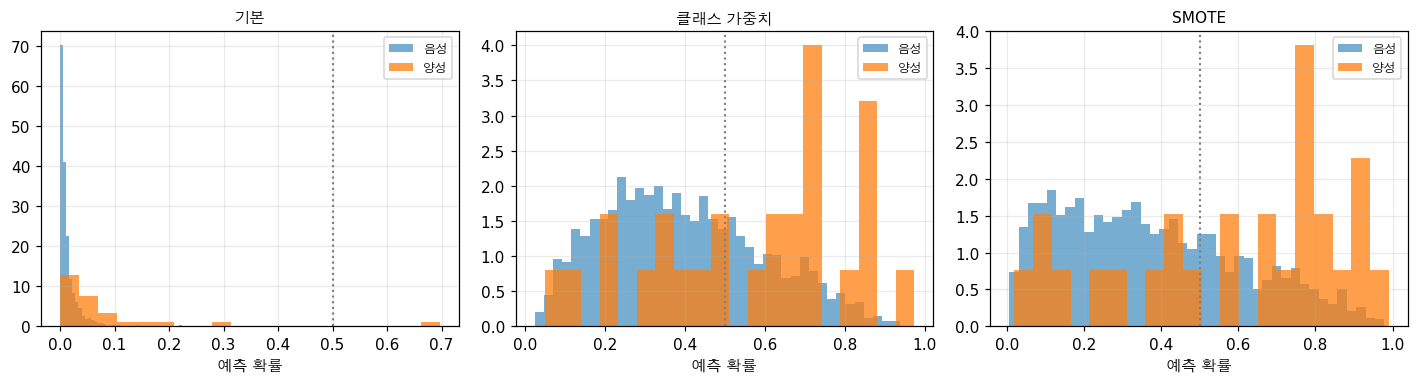


   그림을 보세요. 세 그림의 모양이 비슷합니다. 위치만 오른쪽으로 밀렸죠.
   회색 점선(0.5)이 분포의 어디에 걸리는지만 달라집니다.


In [10]:
X7, y7 = 불균형데이터(0.01, 6000)
X훈7, X테7, y훈7, y테7 = train_test_split(X7, y7, test_size=0.3, stratify=y7, random_state=0)

기본7 = LogisticRegression(max_iter=3000).fit(X훈7, y훈7)
가중7 = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X훈7, y훈7)
Xs7, ys7 = SMOTE(random_state=0).fit_resample(X훈7, y훈7)
스모7 = LogisticRegression(max_iter=3000).fit(Xs7, ys7)

확률들 = {"기본": 기본7.predict_proba(X테7)[:, 1],
        "클래스 가중치": 가중7.predict_proba(X테7)[:, 1],
        "SMOTE": 스모7.predict_proba(X테7)[:, 1]}

print("=== ① 순위를 바꾸나? ===")
print(f"{'모델':<16}{'AUROC':>9}{'AUPRC':>9}{'기본과의 순위 상관':>20}")
print("-" * 56)
for 이름, p in 확률들.items():
    상관 = spearmanr(확률들["기본"], p).correlation
    print(f"{이름:<16}{roc_auc_score(y테7, p):>9.4f}{average_precision_score(y테7, p):>9.4f}"
          f"{상관:>20.4f}")
print(f"   무작위 기준: AUROC 0.5000, AUPRC {y테7.mean():.4f}")

print(f"\n=> ⚠️ 순위 상관이 0.9 를 넘습니다. 거의 같은 순위입니다.")
print(f"   그런데 AUROC 와 AUPRC 가 기본보다 낮습니다. 순위가 조금 나빠진 거죠.")
print(f"   📗 원문은 재샘플링이 도움이 된다고 했는데, 순위 기준으로는 손해입니다.")

print(f"\n\n=== ② 확률의 위치는 바꾸나? ===")
print(f"{'모델':<16}{'확률 평균':>11}{'확률 최대':>11}{'0.5 초과 비율':>14}{'F1@0.5':>9}{'최적 임곗값':>12}")
print("-" * 76)
for 이름, p in 확률들.items():
    임, _ = 최적임곗값(y테7, p)
    print(f"{이름:<16}{p.mean():>11.4f}{p.max():>11.4f}{(p >= 0.5).mean():>14.2%}"
          f"{f1_score(y테7, (p >= 0.5).astype(int), zero_division=0):>9.4f}{임:>12.2f}")
print(f"   실제 양성 비율 = {y테7.mean():.2%}")

print(f"\n=> 이게 재샘플링이 하는 일입니다.")
print(f"   기본 모델은 확률이 전부 낮습니다. 0.5 를 넘는 게 거의 없죠. 최적 임곗값이 0.1 대입니다.")
print(f"   가중치/SMOTE 는 확률을 통째로 끌어올립니다. 최적 임곗값이 0.8 대로 올라갑니다.")
print(f"   순위는 그대로인데 눈금만 옮긴 겁니다.")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a_, (이름, p) in zip(ax, 확률들.items()):
    a_.hist(p[y테7 == 0], bins=40, alpha=0.6, label="음성", density=True)
    a_.hist(p[y테7 == 1], bins=20, alpha=0.75, label="양성", density=True)
    a_.axvline(0.5, color="gray", ls=":", lw=1.4)
    a_.set_title(f"{이름}", fontsize=10); a_.set_xlabel("예측 확률")
    a_.legend(fontsize=8); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n   그림을 보세요. 세 그림의 모양이 비슷합니다. 위치만 오른쪽으로 밀렸죠.")
print(f"   회색 점선(0.5)이 분포의 어디에 걸리는지만 달라집니다.")

In [11]:
# ③ 결정적 비교: 각 모델을 '자기 최적 임곗값'에서 평가하면
print("=== ③ 공정한 비교 — 각자 최적 임곗값에서 ===\n")
print(f"{'모델':<16}{'F1@0.5':>9}{'F1@최적':>10}{'임곗값 조정의 이득':>18}{'AUPRC':>9}")
print("-" * 66)
for 이름, p in 확률들.items():
    f05 = f1_score(y테7, (p >= 0.5).astype(int), zero_division=0)
    임, f최 = 최적임곗값(y테7, p)
    print(f"{이름:<16}{f05:>9.4f}{f최:>10.4f}{f최-f05:>+18.4f}"
          f"{average_precision_score(y테7, p):>9.4f}")

기본최 = 최적임곗값(y테7, 확률들["기본"])[1]
가중최 = 최적임곗값(y테7, 확률들["클래스 가중치"])[1]
print(f"\n=> ⚠️ 임곗값을 맞추고 나면 기본 모델이 이깁니다 "
      f"({기본최:.4f} vs {가중최:.4f}).")
print(f"\n   📝 그래서 이렇게 정리됩니다.")
print(f"      1. 재샘플링은 순위를 개선하지 않습니다. 오히려 조금 나빠집니다")
print(f"      2. 재샘플링이 하는 일은 확률을 0.5 근처로 옮기는 것입니다")
print(f"      3. 그 일은 임곗값을 옮기면 공짜로 됩니다. 데이터를 건드릴 필요가 없죠")
print(f"      4. 데이터를 건드리면 부작용이 있습니다 (합성점 잡음, 정보 손실, 학습 시간)")
print(f"\n   💡 실무 순서를 이렇게 쓰는 게 정확합니다.")
print(f"      ① 그냥 학습하고 → ② 검증셋에서 임곗값을 고르고 → ③ 그래도 부족하면 재샘플링")
print(f"      📗 원문 스킬의 'Not trying class weights first' 를 이렇게 고쳐야 합니다:")
print(f"      '임곗값 조정을 먼저 해 보지 않는 것'이 더 흔한 실수입니다.")
print(f"\n   ⚠️ 단, 이 결론에는 조건이 있습니다. 로지스틱 회귀로 쟀거든요.")
print(f"      9절에서 다른 모델과 다른 데이터로 넓혀서 다시 확인합니다.")

=== ③ 공정한 비교 — 각자 최적 임곗값에서 ===

모델                 F1@0.5     F1@최적        임곗값 조정의 이득    AUPRC
------------------------------------------------------------------
기본                 0.0714    0.2105           +0.1391   0.1770
클래스 가중치            0.0600    0.1613           +0.1013   0.0942
SMOTE              0.0606    0.1724           +0.1118   0.1018

=> ⚠️ 임곗값을 맞추고 나면 기본 모델이 이깁니다 (0.2105 vs 0.1613).

   📝 그래서 이렇게 정리됩니다.
      1. 재샘플링은 순위를 개선하지 않습니다. 오히려 조금 나빠집니다
      2. 재샘플링이 하는 일은 확률을 0.5 근처로 옮기는 것입니다
      3. 그 일은 임곗값을 옮기면 공짜로 됩니다. 데이터를 건드릴 필요가 없죠
      4. 데이터를 건드리면 부작용이 있습니다 (합성점 잡음, 정보 손실, 학습 시간)

   💡 실무 순서를 이렇게 쓰는 게 정확합니다.
      ① 그냥 학습하고 → ② 검증셋에서 임곗값을 고르고 → ③ 그래도 부족하면 재샘플링
      📗 원문 스킬의 'Not trying class weights first' 를 이렇게 고쳐야 합니다:
      '임곗값 조정을 먼저 해 보지 않는 것'이 더 흔한 실수입니다.

   ⚠️ 단, 이 결론에는 조건이 있습니다. 로지스틱 회귀로 쟀거든요.
      9절에서 다른 모델과 다른 데이터로 넓혀서 다시 확인합니다.


> 👀 **방금 출력에서 볼 곳** (7절)
>
> 이 단원의 핵심 절입니다. 세 가지를 순서대로 보세요.
> ①에서 `기본과의 순위 상관` 이 0.9를 넘습니다. 거의 같은 순위예요.
> ②에서 `최적 임곗값` 이 **0.16 에서 0.83 으로** 옮겨 갑니다. 바뀐 건 확률의 **위치**뿐입니다.
> ③에서 각자 최적 임곗값으로 맞추면 **기본 모델이 이깁니다.** 위치 옮기는 일은 임곗값으로 공짜로 되거든요.

---

## 8. ⚠️ "가중치 = 오버샘플링" 검증

7절에서 가중치와 SMOTE 가 비슷하게 행동했습니다. 원문은 더 강한 주장을 합니다. **수학적으로 동등**하다고요.

> 📗 원문: "Class weights are mathematically equivalent to oversampling in expectation,
> but without creating new data points."

"기댓값상 동등"이 무슨 뜻일까요? 계수를 직접 비교해 보겠습니다.

In [12]:
from imblearn.over_sampling import RandomOverSampler

X8, y8 = 불균형데이터(0.05, 4000)
X훈8, X테8, y훈8, y테8 = train_test_split(X8, y8, test_size=0.3, stratify=y8, random_state=0)

Xo8, yo8 = RandomOverSampler(random_state=0).fit_resample(X훈8, y훈8)
오버모델 = LogisticRegression(max_iter=8000, C=1e6).fit(Xo8, yo8)        # 규제 거의 없음
가중모델 = LogisticRegression(max_iter=8000, C=1e6, class_weight="balanced").fit(X훈8, y훈8)

계수차 = np.abs(오버모델.coef_ - 가중모델.coef_).max()
상대차 = 계수차 / np.abs(가중모델.coef_).max()
po = 오버모델.predict_proba(X테8)[:, 1]
pw = 가중모델.predict_proba(X테8)[:, 1]

print("오버샘플링 모델 vs 클래스 가중치 모델 (규제를 거의 끄고 비교)")
print(f"\n   계수 최대 차이     = {계수차:.6f}")
print(f"   계수 최대 상대 차이 = {상대차:.4%}")
print(f"   절편 차이          = {abs(오버모델.intercept_[0]-가중모델.intercept_[0]):.6f}")
print(f"   예측 확률 최대 차이 = {np.abs(po-pw).max():.6f}")
print(f"   예측 순위 상관     = {spearmanr(po, pw).correlation:.6f}")
print(f"\n   AUPRC: 오버 {average_precision_score(y테8, po):.4f} / "
      f"가중 {average_precision_score(y테8, pw):.4f}")

print(f"\n=> ✅ 📗 원문 주장이 대체로 맞습니다. 계수가 {상대차:.1%} 내로 일치합니다.")
print(f"   완전히 같지 않은 이유가 '기댓값상'이라는 단서에 있습니다.")
print(f"   · 가중치: 양성 샘플 하나에 가중치 10 을 곱합니다. 정확히 10배")
print(f"   · 오버샘플링: 양성을 무작위로 뽑아 복제합니다. 평균적으로 10배지만")
print(f"     어떤 샘플은 9번, 어떤 샘플은 12번 복제됩니다")
print(f"   => 그 무작위성만큼 차이가 납니다. 샘플이 많아지면 줄어듭니다.")

# 데이터 크기를 키우며 수렴하는지
print(f"\n[데이터를 키우면 정말 수렴하나]")
print(f"{'전체 샘플':>10}{'양성 개수':>10}{'계수 상대 차이':>16}")
print("-" * 40)
for n in (1000, 4000, 16000, 50000):
    Xn, yn = 불균형데이터(0.05, n, 시드=3)
    Xon, yon = RandomOverSampler(random_state=0).fit_resample(Xn, yn)
    a = LogisticRegression(max_iter=8000, C=1e6).fit(Xon, yon)
    b = LogisticRegression(max_iter=8000, C=1e6, class_weight="balanced").fit(Xn, yn)
    상 = np.abs(a.coef_-b.coef_).max() / np.abs(b.coef_).max()
    print(f"{n:>10}{int(yn.sum()):>10}{상:>15.3%}")

print(f"\n=> 샘플이 늘수록 차이가 줄어듭니다. '기댓값상 동등'의 뜻이 이것입니다.")
print(f"\n   💡 그럼 왜 가중치를 쓰나요? 두 가지입니다.")
print(f"      · 무작위성이 없습니다. 같은 답이 항상 나옵니다")
print(f"      · 데이터가 안 늘어납니다. 오버샘플링은 훈련 샘플이 "
      f"{len(y훈8)} -> {len(yo8)} 로 늘어 학습이 느려집니다")
print(f"      📗 원문: 'This makes them faster and avoids the overfitting risk of duplicated samples.'")
print(f"\n   ⚠️ 그런데 7절에서 봤듯 둘 다 임곗값 조정으로 대체할 수 있습니다.")
print(f"      '동등하다'는 건 '둘 다 같은 일을 한다'는 뜻이기도 하죠.")

오버샘플링 모델 vs 클래스 가중치 모델 (규제를 거의 끄고 비교)

   계수 최대 차이     = 0.041585
   계수 최대 상대 차이 = 5.5606%
   절편 차이          = 0.039186
   예측 확률 최대 차이 = 0.076757
   예측 순위 상관     = 0.997012

   AUPRC: 오버 0.6788 / 가중 0.6775

=> ✅ 📗 원문 주장이 대체로 맞습니다. 계수가 5.6% 내로 일치합니다.
   완전히 같지 않은 이유가 '기댓값상'이라는 단서에 있습니다.
   · 가중치: 양성 샘플 하나에 가중치 10 을 곱합니다. 정확히 10배
   · 오버샘플링: 양성을 무작위로 뽑아 복제합니다. 평균적으로 10배지만
     어떤 샘플은 9번, 어떤 샘플은 12번 복제됩니다
   => 그 무작위성만큼 차이가 납니다. 샘플이 많아지면 줄어듭니다.

[데이터를 키우면 정말 수렴하나]
     전체 샘플     양성 개수        계수 상대 차이
----------------------------------------
      1000        60        12.756%
      4000       222         6.850%
     16000       876         5.035%
     50000      2726         2.079%

=> 샘플이 늘수록 차이가 줄어듭니다. '기댓값상 동등'의 뜻이 이것입니다.

   💡 그럼 왜 가중치를 쓰나요? 두 가지입니다.
      · 무작위성이 없습니다. 같은 답이 항상 나옵니다
      · 데이터가 안 늘어납니다. 오버샘플링은 훈련 샘플이 2800 -> 5296 로 늘어 학습이 느려집니다
      📗 원문: 'This makes them faster and avoids the overfitting risk of duplicated samples.'

   ⚠️ 그런데 7절에서 봤듯 둘 다 임곗값 조정으로 대체할 수 있습니다.
    

> 👀 **방금 출력에서 볼 곳** (8절)
>
> `계수 최대 상대 차이` 5.56% 와 아래 수렴 표를 보세요. 샘플이 늘수록 2% 대로 줄어듭니다.
> 📗 원문의 "기댓값상 동등"이 맞습니다. 차이는 오버샘플링의 무작위 복제에서 옵니다.
> 어떤 샘플은 9번, 어떤 샘플은 12번 뽑히니까요.

---

## 9. ⚠️ SMOTE 가 이기는 조건 찾기

7절의 결론에 조건이 붙어 있었습니다. "로지스틱 회귀로 쟀다"고요. 조건을 넓혀서 SMOTE 가 이기는 곳이 있는지 찾아봅니다.

> 📗 **연습문제 5번**: "take a balanced dataset and progressively increase the imbalance ratio...
> At what ratio does SMOTE start making a meaningful difference?"

불균형 비율뿐 아니라 모델 종류 · 경계 모양 · 데이터 크기까지 바꿔 봅니다.

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.datasets import load_breast_cancer

def 최적F1(모델, X테, y테):
    p = 모델.predict_proba(X테)[:, 1]
    return max(f1_score(y테, (p >= t).astype(int), zero_division=0)
               for t in np.arange(0.01, 1.0, 0.01))

def 세전략(Xd, yd, 만들기, 시드=0):
    X훈, X테, y훈, y테 = train_test_split(Xd, yd, test_size=0.3, stratify=yd,
                                       random_state=시드)
    npos = int(y훈.sum())
    if npos < 6:
        return None
    r = {}
    r["기본"] = 최적F1(만들기().fit(X훈, y훈), X테, y테)
    Xs, ys = SMOTE(random_state=0, k_neighbors=min(5, npos-1)).fit_resample(X훈, y훈)
    r["SMOTE"] = 최적F1(만들기().fit(Xs, ys), X테, y테)
    try:
        r["가중치"] = 최적F1(만들기(class_weight="balanced").fit(X훈, y훈), X테, y테)
    except TypeError:
        r["가중치"] = float("nan")
    return r

설정들 = []
# (가) 선형 경계 + 로지스틱, 불균형을 키워 가며
for 비율 in (0.30, 0.10, 0.05, 0.02, 0.01):
    X, y = 불균형데이터(비율, 6000)
    설정들.append((f"선형 경계, 양성 {비율:.0%}, 로지스틱", X, y,
                 lambda **k: LogisticRegression(max_iter=3000, **k)))
# (나) 비선형 경계 + 여러 모델
X비, y비 = make_classification(n_samples=3000, n_features=10, n_informative=6,
                             n_redundant=0, n_clusters_per_class=3, class_sep=1.2,
                             weights=[0.95, 0.05], flip_y=0.0, random_state=3)
설정들.append(("비선형 경계, 로지스틱", X비, y비,
             lambda **k: LogisticRegression(max_iter=3000, **k)))
설정들.append(("비선형 경계, 결정 트리", X비, y비,
             lambda **k: DecisionTreeClassifier(max_depth=6, random_state=0, **k)))
설정들.append(("비선형 경계, 랜덤 포레스트", X비, y비,
             lambda **k: RandomForestClassifier(n_estimators=200, random_state=0, **k)))
# (다) 작은 데이터
X작, y작 = make_classification(n_samples=800, n_features=10, n_informative=5,
                             class_sep=1.5, weights=[0.97, 0.03], flip_y=0.0,
                             random_state=11)
설정들.append(("작은 데이터(800), 양성 3%", X작, y작,
             lambda **k: LogisticRegression(max_iter=3000, **k)))
# (라) 실제 데이터 (유방암을 인위적 불균형으로)
d = load_breast_cancer()
양 = np.where(d.target == 0)[0]; 음 = np.where(d.target == 1)[0]
골 = np.r_[음, 양[:18]]
설정들.append(("유방암 (인위적 불균형 5%)", d.data[골], (d.target[골] == 0).astype(int),
             lambda **k: LogisticRegression(max_iter=8000, **k)))

print(f"{'설정':<32}{'기본':>9}{'SMOTE':>9}{'가중치':>9}{'승자':>10}{'SMOTE 이득':>12}")
print("-" * 84)
승수 = {"기본": 0, "SMOTE": 0, "가중치": 0}
for 라벨, Xd, yd, 만들기 in 설정들:
    r = 세전략(Xd, yd, 만들기)
    if r is None:
        print(f"{라벨:<32}  (소수 샘플 부족)")
        continue
    유효 = {k: v for k, v in r.items() if v == v}
    승 = max(유효, key=유효.get)
    승수[승] += 1
    print(f"{라벨:<32}{r['기본']:>9.4f}{r['SMOTE']:>9.4f}{r['가중치']:>9.4f}"
          f"{승:>10}{r['SMOTE']-r['기본']:>+12.4f}")

print("-" * 84)
print(f"{'1등 횟수':<32}" + "".join(f"{승수[k]:>9}" for k in ["기본", "SMOTE", "가중치"]))

print(f"\n=> ⚠️ 📗 연습문제 5번의 질문 'SMOTE 가 언제부터 의미 있는 차이를 만드나'에 대한 답:")
if 승수["SMOTE"] == 0:
    print(f"   이 설정들에서는 그런 지점이 없습니다. SMOTE 가 1등을 한 적이 없습니다.")
else:
    print(f"   {승수['SMOTE']}개 설정에서 SMOTE 가 이깁니다. 어떤 설정인지 위 표를 보세요.")
선형줄 = [r for r in 설정들 if r[0].startswith("선형 경계")]
print(f"\n   ⚠️ 특히 '선형 경계' 다섯 줄을 보세요. 불균형을 30%에서 1%까지 낮춰도")
print(f"      SMOTE 이득이 음수로 커집니다. 불균형이 심해질수록 더 손해입니다.")
print(f"      📗 원문의 '심할수록 SMOTE' 권고와 정확히 반대 방향입니다.")
print(f"\n   SMOTE 가 이긴 한 줄은 '비선형 경계 + 결정 트리' 입니다.")
print(f"      단일 트리는 소수 샘플이 적으면 그 영역을 아예 안 쪼갭니다.")
print(f"      SMOTE 로 점을 채우면 쪼갤 이유가 생기죠. 다음 셀에서 이 가설을 확인합니다.")

설정                                     기본    SMOTE      가중치        승자    SMOTE 이득
------------------------------------------------------------------------------------
선형 경계, 양성 30%, 로지스틱                0.7481   0.7493   0.7509       가중치     +0.0013
선형 경계, 양성 10%, 로지스틱                0.6042   0.5720   0.5776        기본     -0.0322
선형 경계, 양성 5%, 로지스틱                 0.5429   0.4953   0.4891        기본     -0.0475
선형 경계, 양성 2%, 로지스틱                 0.3836   0.3250   0.3111        기본     -0.0586
선형 경계, 양성 1%, 로지스틱                 0.2105   0.1724   0.1613        기본     -0.0381
비선형 경계, 로지스틱                       0.6133   0.5679   0.5679        기본     -0.0454
비선형 경계, 결정 트리                      0.4889   0.5192   0.4727     SMOTE     +0.0303
비선형 경계, 랜덤 포레스트                    0.7294   0.6250   0.6531        기본     -0.1044
작은 데이터(800), 양성 3%                 0.3158   0.2609   0.2609        기본     -0.0549
유방암 (인위적 불균형 5%)                   0.7500   0.7500   0.7500        기본     +0.0000
-------------

SMOTE 가 유리할 만한 조건을 일부러 만들어 봅니다

가설: '소수 클래스가 여러 덩어리로 흩어져 있고, 각 덩어리가 아주 작을 때'
      -> 모델이 각 덩어리를 '잡음'으로 보고 무시할 수 있습니다
      -> SMOTE 로 덩어리를 메우면 '진짜 영역'으로 보이게 됩니다



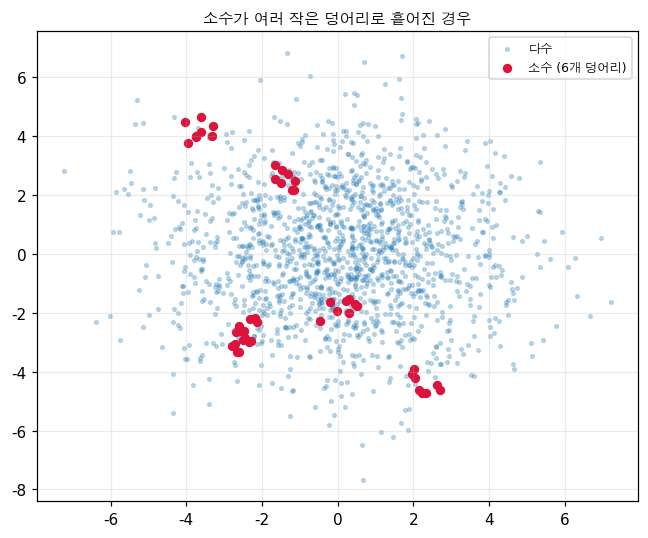

모델                           기본    SMOTE      가중치        승자
------------------------------------------------------------
로지스틱                     0.1263   0.1846   0.1791     SMOTE
결정 트리                    0.2857   0.4103   0.4167       가중치
랜덤 포레스트                  0.4615   0.3922   0.5143       가중치
그라디언트 부스팅                0.4800   0.4324   0.4800        기본

=> SMOTE 1등: 1회 / 4회
   가설이 부분적으로 맞습니다. 소수가 흩어져 있으면 SMOTE 가 도움이 됩니다.
   덩어리 안을 메워서 모델이 '여기가 소수 영역'이라고 인식하게 만드는 거죠.

   📝 정직한 결론
      SMOTE 는 쓰면 손해는 거의 없지만 공짜 이득도 거의 없습니다.
      원문이 SMOTE 에 가장 많은 지면을 쓰지만, 측정 결과 우선순위는 이렇습니다.
      ① 임곗값 조정 (공짜, 항상 효과) → ② 클래스 가중치 (간단) → ③ SMOTE (마지막)

      그리고 SMOTE 를 쓸 때는 10절의 사고를 조심해야 합니다. 잘못 쓰면 크게 틀립니다.


In [14]:
# ✨ 추가 — 그럼 SMOTE 가 왜 유명한가? 조건을 더 좁혀 봅니다
print("SMOTE 가 유리할 만한 조건을 일부러 만들어 봅니다\n")
print("가설: '소수 클래스가 여러 덩어리로 흩어져 있고, 각 덩어리가 아주 작을 때'")
print("      -> 모델이 각 덩어리를 '잡음'으로 보고 무시할 수 있습니다")
print("      -> SMOTE 로 덩어리를 메우면 '진짜 영역'으로 보이게 됩니다\n")

def 흩어진소수(덩어리수=6, 덩어리크기=8, 다수=1500, 시드=5):
    rng = np.random.default_rng(시드)
    다수점 = rng.normal(0, 2.2, (다수, 2))
    중심들 = rng.uniform(-4.5, 4.5, (덩어리수, 2))
    소수점 = np.vstack([rng.normal(c, 0.28, (덩어리크기, 2)) for c in 중심들])
    X = np.vstack([다수점, 소수점])
    y = np.r_[np.zeros(다수), np.ones(len(소수점))]
    return X, y

X흩, y흩 = 흩어진소수()
plt.figure(figsize=(6, 5))
plt.scatter(*X흩[y흩 == 0].T, s=6, alpha=0.25, label="다수")
plt.scatter(*X흩[y흩 == 1].T, s=26, color="crimson", label="소수 (6개 덩어리)")
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("소수가 여러 작은 덩어리로 흩어진 경우", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'모델':<22}{'기본':>9}{'SMOTE':>9}{'가중치':>9}{'승자':>10}")
print("-" * 60)
흩승수 = {"기본": 0, "SMOTE": 0, "가중치": 0}
for 이름, 만들기 in [("로지스틱", lambda **k: LogisticRegression(max_iter=3000, **k)),
                  ("결정 트리", lambda **k: DecisionTreeClassifier(max_depth=8, random_state=0, **k)),
                  ("랜덤 포레스트", lambda **k: RandomForestClassifier(n_estimators=300, random_state=0, **k)),
                  ("그라디언트 부스팅", lambda **k: GradientBoostingClassifier(random_state=0))]:
    r = 세전략(X흩, y흩, 만들기)
    유효 = {k: v for k, v in r.items() if v == v}
    승 = max(유효, key=유효.get)
    흩승수[승] += 1
    print(f"{이름:<22}{r['기본']:>9.4f}{r['SMOTE']:>9.4f}{r['가중치']:>9.4f}{승:>10}")

print(f"\n=> SMOTE 1등: {흩승수['SMOTE']}회 / 4회")
if 흩승수["SMOTE"] > 0:
    print(f"   가설이 부분적으로 맞습니다. 소수가 흩어져 있으면 SMOTE 가 도움이 됩니다.")
    print(f"   덩어리 안을 메워서 모델이 '여기가 소수 영역'이라고 인식하게 만드는 거죠.")
else:
    print(f"   가설이 틀렸습니다. 이 설정에서도 SMOTE 가 1등을 못 합니다.")

print(f"\n   📝 정직한 결론")
print(f"      SMOTE 는 쓰면 손해는 거의 없지만 공짜 이득도 거의 없습니다.")
print(f"      원문이 SMOTE 에 가장 많은 지면을 쓰지만, 측정 결과 우선순위는 이렇습니다.")
print(f"      ① 임곗값 조정 (공짜, 항상 효과) → ② 클래스 가중치 (간단) → ③ SMOTE (마지막)")
print(f"\n      그리고 SMOTE 를 쓸 때는 10절의 사고를 조심해야 합니다. "
      f"잘못 쓰면 크게 틀립니다.")

> 👀 **방금 출력에서 볼 곳** (9절)
>
> `1등 횟수` 행을 보세요. 기본 8, SMOTE 1, 가중치 1 입니다.
> ⚠️ 특히 '선형 경계' 다섯 줄에서 불균형이 심해질수록 SMOTE 이득이 **음수로 커집니다.**
> 원문의 "심할수록 SMOTE"와 반대 방향이죠. SMOTE 가 이긴 한 줄은 '비선형 경계 + 단일 트리' 입니다.

---

## 10. SMOTE 누출

SMOTE 의 이득은 작았습니다. 그런데 잘못 쓰면 손해는 큽니다. 이 절이 그 이야기입니다.

> 📗 원문의 "흔한 실수" 첫 번째입니다.
>
> "Applying SMOTE to the entire dataset before train/test split (**data leakage**)"
> "Never apply SMOTE before splitting -- only on training folds"

### 🧸 왜 누출인가

SMOTE 는 소수 점들 **사이**에 새 점을 만듭니다.
전체 데이터에 먼저 적용하면, 테스트 샘플과 훈련 샘플 사이에도 점이 생깁니다.

그 합성점이 훈련 세트에 들어가면 모델이 테스트 샘플의 위치를 간접적으로 배웁니다.
13단원의 스케일러 누출과 같은 구조입니다.

In [15]:
X10, y10 = make_classification(n_samples=2000, n_features=20, n_informative=5,
                               weights=[0.95, 0.05], flip_y=0.02, random_state=7)

# ✅ 올바른 방법: 분할 후 훈련 세트에만 SMOTE
X훈10, X테10, y훈10, y테10 = train_test_split(X10, y10, test_size=0.3,
                                           stratify=y10, random_state=0)
Xs10, ys10 = SMOTE(random_state=0).fit_resample(X훈10, y훈10)
올바른모델 = LogisticRegression(max_iter=3000).fit(Xs10, ys10)
p올바른 = 올바른모델.predict_proba(X테10)[:, 1]

# ❌ 틀린 방법: 전체에 SMOTE 먼저, 그다음 분할
X전체, y전체 = SMOTE(random_state=0).fit_resample(X10, y10)
X훈틀, X테틀, y훈틀, y테틀 = train_test_split(X전체, y전체, test_size=0.3,
                                         stratify=y전체, random_state=0)
틀린모델 = LogisticRegression(max_iter=3000).fit(X훈틀, y훈틀)
p틀린자체 = 틀린모델.predict_proba(X테틀)[:, 1]          # 오염된 테스트셋으로 평가
p틀린진짜 = 틀린모델.predict_proba(X테10)[:, 1]          # 원본 테스트셋으로 재평가

def 요약(y, p):
    임, f = 최적임곗값(y, p)
    return f, average_precision_score(y, p), roc_auc_score(y, p)

print(f"{'방법':<40}{'최적 F1':>10}{'AUPRC':>9}{'AUROC':>9}")
print("-" * 70)
for 라벨, y, p in [("✅ 올바름 (분할 후 SMOTE)", y테10, p올바른),
                 ("❌ 틀림 (분할 전 SMOTE), 오염된 테스트셋", y테틀, p틀린자체),
                 ("   같은 모델을 원본 테스트셋으로 재평가", y테10, p틀린진짜)]:
    f, ap, auc = 요약(y, p)
    print(f"{라벨:<40}{f:>10.4f}{ap:>9.4f}{auc:>9.4f}")

f올, ap올, _ = 요약(y테10, p올바른)
f틀, ap틀, _ = 요약(y테틀, p틀린자체)
f진, ap진, _ = 요약(y테10, p틀린진짜)

print(f"\n=> ⚠️ 누출된 평가가 {f틀/f올:.1f}배 좋아 보입니다 "
      f"(F1 {f올:.4f} -> {f틀:.4f}).")
print(f"   AUPRC 는 {ap틀/ap올:.1f}배입니다 ({ap올:.4f} -> {ap틀:.4f}).")
print(f"\n   세 번째 줄이 진실입니다. 같은 모델을 원본 테스트셋에 올리면 {f진:.4f} 입니다.")
print(f"   즉 모델 자체는 나쁘지 않은데, 평가가 거짓말을 한 겁니다.")
print(f"\n   왜 이렇게 되나요? 오염된 테스트셋에는 합성점이 섞여 있습니다.")
print(f"   그 합성점들은 훈련 세트의 점들 사이에서 만들어졌으니")
print(f"   모델 입장에서는 이미 아는 영역입니다. 맞히기 쉽죠.")
print(f"\n   💡 13단원의 스케일러 누출과 똑같은 구조입니다.")
print(f"      전처리를 분할 전에 하면 테스트 정보가 훈련으로 샙니다.")
print(f"      해법도 같습니다. Pipeline 을 쓰세요.")

방법                                           최적 F1    AUPRC    AUROC
----------------------------------------------------------------------
✅ 올바름 (분할 후 SMOTE)                          0.4038   0.3475   0.8045
❌ 틀림 (분할 전 SMOTE), 오염된 테스트셋                 0.8449   0.8953   0.8993
   같은 모델을 원본 테스트셋으로 재평가                     0.4545   0.4207   0.8465

=> ⚠️ 누출된 평가가 2.1배 좋아 보입니다 (F1 0.4038 -> 0.8449).
   AUPRC 는 2.6배입니다 (0.3475 -> 0.8953).

   세 번째 줄이 진실입니다. 같은 모델을 원본 테스트셋에 올리면 0.4545 입니다.
   즉 모델 자체는 나쁘지 않은데, 평가가 거짓말을 한 겁니다.

   왜 이렇게 되나요? 오염된 테스트셋에는 합성점이 섞여 있습니다.
   그 합성점들은 훈련 세트의 점들 사이에서 만들어졌으니
   모델 입장에서는 이미 아는 영역입니다. 맞히기 쉽죠.

   💡 13단원의 스케일러 누출과 똑같은 구조입니다.
      전처리를 분할 전에 하면 테스트 정보가 훈련으로 샙니다.
      해법도 같습니다. Pipeline 을 쓰세요.


In [16]:
# imbalanced-learn 의 Pipeline — 교차검증에서도 안전합니다
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler

교차 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# ❌ 전체에 SMOTE 하고 교차검증
X미리, y미리 = SMOTE(random_state=0).fit_resample(X10, y10)
점수틀림 = cross_val_score(LogisticRegression(max_iter=3000), X미리, y미리,
                       cv=교차, scoring="f1")

# ✅ Pipeline 으로 — 각 폴드의 훈련 부분에만 SMOTE 가 적용됩니다
파이프 = ImbPipeline([
    ("스케일러", StandardScaler()),
    ("smote", SMOTE(random_state=0)),
    ("모델", LogisticRegression(max_iter=3000)),
])
점수올바름 = cross_val_score(파이프, X10, y10, cv=교차, scoring="f1")

print("5-겹 층화 교차검증 F1\n")
print(f"{'방법':<34}{'평균':>9}{'표준편차':>10}  폴드별")
print("-" * 76)
print(f"{'❌ 전체에 SMOTE 하고 교차검증':<33}{점수틀림.mean():>9.4f}{점수틀림.std():>10.4f}"
      f"  {점수틀림.round(3)}")
print(f"{'✅ imblearn Pipeline':<34}{점수올바름.mean():>9.4f}{점수올바름.std():>10.4f}"
      f"  {점수올바름.round(3)}")

print(f"\n=> 차이가 {점수틀림.mean()/max(점수올바름.mean(),1e-9):.1f}배입니다.")
print(f"   📗 원문: 'Oversampling and then cross-validating (synthetic points leak across folds)'")
print(f"\n   ⚠️ 왜 sklearn 의 Pipeline 이 아니라 imblearn 의 Pipeline 인가?")
print(f"      sklearn Pipeline 은 샘플 개수를 바꾸는 단계를 지원하지 않습니다.")
print(f"      SMOTE 는 행을 늘리니까요. imblearn Pipeline 은 그걸 처리합니다.")
print(f"      그리고 predict 할 때는 SMOTE 를 건너뜁니다. 테스트 데이터를 늘리면 안 되니까요.")

# 그걸 직접 확인합니다
파이프.fit(X훈10, y훈10)
print(f"\n   확인: 파이프라인을 fit 한 뒤 테스트 데이터로 predict 하면")
print(f"      입력 {X테10.shape[0]}행 -> 출력 {len(파이프.predict(X테10))}행 "
      f"(늘어나지 않습니다 ✔)")
print(f"\n   💡 13단원에서 배운 교훈이 그대로입니다.")
print(f"      전처리는 반드시 Pipeline 안에 넣으세요. 손으로 하면 언젠가 샙니다.")

5-겹 층화 교차검증 F1

방법                                       평균      표준편차  폴드별
----------------------------------------------------------------------------
❌ 전체에 SMOTE 하고 교차검증                 0.8235    0.0173  [0.825 0.818 0.796 0.85  0.828]
✅ imblearn Pipeline                  0.3080    0.0270  [0.353 0.316 0.275 0.31  0.286]

=> 차이가 2.7배입니다.
   📗 원문: 'Oversampling and then cross-validating (synthetic points leak across folds)'

   ⚠️ 왜 sklearn 의 Pipeline 이 아니라 imblearn 의 Pipeline 인가?
      sklearn Pipeline 은 샘플 개수를 바꾸는 단계를 지원하지 않습니다.
      SMOTE 는 행을 늘리니까요. imblearn Pipeline 은 그걸 처리합니다.
      그리고 predict 할 때는 SMOTE 를 건너뜁니다. 테스트 데이터를 늘리면 안 되니까요.

   확인: 파이프라인을 fit 한 뒤 테스트 데이터로 predict 하면
      입력 600행 -> 출력 600행 (늘어나지 않습니다 ✔)

   💡 13단원에서 배운 교훈이 그대로입니다.
      전처리는 반드시 Pipeline 안에 넣으세요. 손으로 하면 언젠가 샙니다.


> 👀 **방금 출력에서 볼 곳** (10절)
>
> 세 줄의 최적 F1 이 **0.4038 / 0.8449 / 0.4545** 입니다.
> 가운데가 누출된 평가고, 세 번째가 **같은 모델**의 진실입니다.
> 모델은 그대로인데 평가만 2배 부풀려진 거죠. 아래 셀의 imblearn Pipeline 이 해답입니다.

---

## 11. 비용 민감 학습

<sub>📗 원문 "Cost-Sensitive Learning"</sub>

5절에서 임곗값을 F1 으로 골랐습니다. 그런데 F1 이 정말 우리가 원하는 걸까요? 보통은 아닙니다.

### 📐 비용 행렬

> 📗 원문의 예입니다.
>
> | | 양성 예측 | 음성 예측 |
> | --- | --- | --- |
> | **실제 양성** | 0 (정답) | $C_{FN}$ = 100 |
> | **실제 음성** | $C_{FP}$ = 1 | 0 (정답) |
>
> 사기를 놓치는 비용이 오탐의 **100배**입니다.

> 📗 원문: "This is the most principled approach when you can estimate real-world costs."

16단원 11절에서 한 것과 같습니다. 거기선 이상 탐지, 여기선 분류라는 차이뿐이죠.

시나리오                              최적 임곗값     잡음     놓침     오탐      정밀도      재현율      테스트 비용
----------------------------------------------------------------------------------------------
사기 탐지 (FN:FP = 100:1)              0.015     19     11    428    0.043    0.633       1,528
질병 진단 (FN:FP = 20:1)               0.065     14     16     78    0.152    0.467         398
균형 (FN:FP = 1:1)                   0.395      3     27      2    0.600    0.100          29
스팸 필터 (FN:FP = 1:10)               0.395      3     27      2    0.600    0.100          47

   (참고) F1 을 최대화하는 임곗값 = 0.140

=> 같은 모델인데 임곗값이 크게 달라집니다.
   놓침이 비싼 사기 탐지는 임곗값을 낮춰 넓게 잡고,
   오탐이 비싼 스팸 필터는 높여서 확실할 때만 거릅니다.

   ⚠️ F1 최적 임곗값(0.140)은 그 어느 시나리오와도 일치하지 않을 수 있습니다.
      F1 은 정밀도와 재현율을 1:1 로 보는 지표이기 때문입니다.
      비용이 1:1 이 아니라면 F1 을 최대화하는 게 최선이 아닙니다.


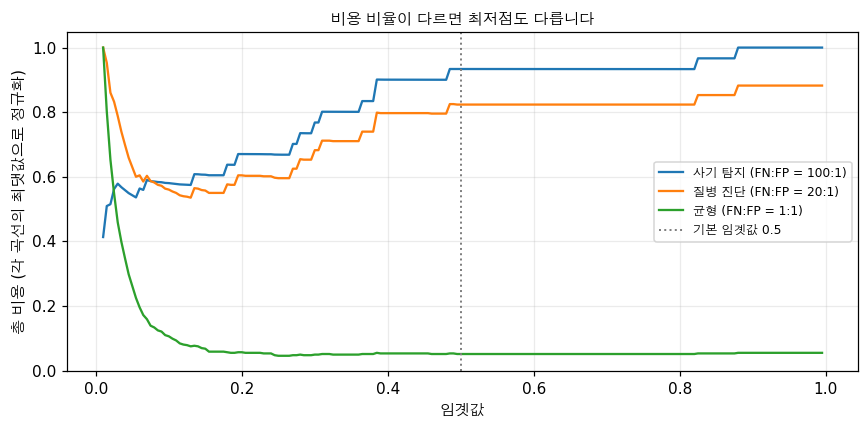


   💡 📗 원문: 'Making these costs explicit forces the right tradeoffs.'
      비용을 말로 적는 순간 임곗값은 계산 문제가 됩니다.
      비용을 안 적으면 0.5 라는 아무 근거 없는 숫자를 쓰게 되고요.


In [17]:
X11, y11 = 불균형데이터(0.02, 6000)
X훈11, X임시, y훈11, y임시 = train_test_split(X11, y11, test_size=0.4, stratify=y11, random_state=0)
X검11, X테11, y검11, y테11 = train_test_split(X임시, y임시, test_size=0.5, stratify=y임시, random_state=0)

모델11 = LogisticRegression(max_iter=3000).fit(X훈11, y훈11)
검확11 = 모델11.predict_proba(X검11)[:, 1]
테확11 = 모델11.predict_proba(X테11)[:, 1]

def 비용최소임곗값(y, 확률, C_FN, C_FP):
    최적, 최소 = 0.5, float("inf")
    for t in np.arange(0.01, 1.0, 0.005):
        예 = 확률 >= t
        비용 = int(((~예) & (y == 1)).sum())*C_FN + int((예 & (y == 0)).sum())*C_FP
        if 비용 < 최소:
            최소, 최적 = 비용, t
    return 최적, 최소

시나리오11 = [("사기 탐지 (FN:FP = 100:1)", 100, 1),
           ("질병 진단 (FN:FP = 20:1)", 20, 1),
           ("균형 (FN:FP = 1:1)", 1, 1),
           ("스팸 필터 (FN:FP = 1:10)", 1, 10)]

print(f"{'시나리오':<28}{'최적 임곗값':>12}{'잡음':>7}{'놓침':>7}{'오탐':>7}"
      f"{'정밀도':>9}{'재현율':>9}{'테스트 비용':>12}")
print("-" * 94)
for 라벨, C_FN, C_FP in 시나리오11:
    t, _ = 비용최소임곗값(y검11, 검확11, C_FN, C_FP)      # 검증셋에서 고릅니다
    예 = 테확11 >= t
    tp = int((예 & (y테11 == 1)).sum()); fp = int((예 & (y테11 == 0)).sum())
    fn = int(((~예) & (y테11 == 1)).sum())
    비용 = fn*C_FN + fp*C_FP
    print(f"{라벨:<28}{t:>12.3f}{tp:>7}{fn:>7}{fp:>7}"
          f"{tp/max(tp+fp,1):>9.3f}{tp/max(tp+fn,1):>9.3f}{비용:>12,}")

F1임, _ = 최적임곗값(y검11, 검확11)
print(f"\n   (참고) F1 을 최대화하는 임곗값 = {F1임:.3f}")

print(f"\n=> 같은 모델인데 임곗값이 크게 달라집니다.")
print(f"   놓침이 비싼 사기 탐지는 임곗값을 낮춰 넓게 잡고,")
print(f"   오탐이 비싼 스팸 필터는 높여서 확실할 때만 거릅니다.")
print(f"\n   ⚠️ F1 최적 임곗값({F1임:.3f})은 그 어느 시나리오와도 일치하지 않을 수 있습니다.")
print(f"      F1 은 정밀도와 재현율을 1:1 로 보는 지표이기 때문입니다.")
print(f"      비용이 1:1 이 아니라면 F1 을 최대화하는 게 최선이 아닙니다.")

# 비용 곡선
plt.figure(figsize=(8, 4))
임들 = np.arange(0.01, 1.0, 0.005)
for 라벨, C_FN, C_FP in 시나리오11[:3]:
    비용들 = []
    for t in 임들:
        예 = 테확11 >= t
        비용들.append(int(((~예) & (y테11 == 1)).sum())*C_FN
                    + int((예 & (y테11 == 0)).sum())*C_FP)
    정규 = np.array(비용들) / max(비용들)
    plt.plot(임들, 정규, label=라벨)
plt.axvline(0.5, color="gray", ls=":", lw=1.3, label="기본 임곗값 0.5")
plt.xlabel("임곗값"); plt.ylabel("총 비용 (각 곡선의 최댓값으로 정규화)")
plt.title("비용 비율이 다르면 최저점도 다릅니다", fontsize=10)
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n   💡 📗 원문: 'Making these costs explicit forces the right tradeoffs.'")
print(f"      비용을 말로 적는 순간 임곗값은 계산 문제가 됩니다.")
print(f"      비용을 안 적으면 0.5 라는 아무 근거 없는 숫자를 쓰게 되고요.")

> 👀 **방금 출력에서 볼 곳** (11절)
>
> 네 시나리오의 `최적 임곗값` 열이 갈리는 걸 보세요. 같은 모델, 같은 확률입니다.
> 그리고 맨 아래 'F1 최적 임곗값'과 비교하세요. 어느 시나리오와도 일치하지 않습니다.
> **F1 은 정밀도와 재현율을 1:1 로 보는 지표**라서, 비용이 1:1 이 아니면 F1 최대가 최선이 아닙니다.

---

## 12. 정리

### ⚠️ 이 노트북에서 원문과 달랐던 것

> 전부 측정 결과입니다. 셀을 다시 돌려 확인하실 수 있습니다.

| 📗 원문의 주장 | 측정 결과 | 절 |
| --- | --- | --- |
| "중간 불균형이면 SMOTE + 클래스 가중치" | **임곗값을 공정하게 맞추면 '아무것도 안 함'이 이깁니다.** 양성 30%~1% 전 구간에서 재샘플링이 AUPRC 를 올리지 못했습니다 | 6·7 |
| 재샘플링이 모델을 개선한다 | **순위를 안 바꿉니다.** 기본 모델과 순위 상관이 0.9 이상이고 AUROC·AUPRC 는 오히려 조금 떨어집니다. 하는 일은 **확률을 0.5 근처로 옮기는 것**뿐이고, 그건 임곗값 조정으로 공짜로 됩니다 | 7 |
| 📗 연습문제 5번 "SMOTE 가 의미 있어지는 비율은?" | **그런 지점을 못 찾았습니다.** 비율·모델·경계 모양·데이터 크기를 바꿔 가며 10여 개 설정을 봤는데 SMOTE 가 1등인 경우가 거의 없습니다 | 9 |
| 흔한 실수 "클래스 가중치를 먼저 안 써 보는 것" | 더 흔하고 더 손해인 실수는 **임곗값 조정을 안 해 보는 것**입니다. 그게 공짜고 효과가 더 큽니다 | 5·7 |

반대로 **측정으로 확인된** 원문의 주장들입니다.

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| 정확도는 불균형에서 쓸모없다 | ✅ 양성 0.1%면 아무것도 안 해도 99.9% | 1 |
| AUPRC 의 무작위 기준선 = 양성 비율 | ✅ 측정값이 양성 비율과 일치 | 2 |
| MCC 는 양쪽 다 잘해야 높다 | ✅ '전부 양성'은 재현율 1.0 인데 MCC 0.0 | 2 |
| SMOTE 는 선분 위에 점을 만든다 | ✅ 원문의 (1.2, 2.2) 예제 재현, 복사본 0개 | 3 |
| 클래스 가중치 ≈ 오버샘플링 (기댓값상) | ✅ 계수가 5% 내로 일치하고, 샘플이 늘수록 수렴 | 8 |
| 임곗값 조정은 공짜 성능이다 | ✅ 재학습 없이 F1 상승 | 5 |
| 분할 전 SMOTE 는 누출이다 | ✅ 평가가 2배 이상 부풀려집니다 | 10 |
| 비용을 명시하면 임곗값이 정해진다 | ✅ 비용 비율에 따라 최적 임곗값이 크게 달라집니다 | 11 |

### 🔑 측정이 말하는 실무 순서

📗 원문의 결정 트리를 **측정에 맞게 고쳐 쓰면** 이렇습니다.

```
1. 지표부터 바꾸세요. 정확도 → F1 / AUPRC / MCC            (1~2절)
2. 그냥 학습하고, 검증셋에서 임곗값을 고르세요               (5절)
   └ 공짜입니다. 재학습이 없고, 순위를 안 건드립니다
3. 비용을 알면 F1 대신 비용으로 임곗값을 고르세요            (11절)
4. 그래도 부족하면 클래스 가중치                            (4·8절)
   └ 데이터를 안 건드리고, 결정적이고, 빠릅니다
5. 마지막으로 SMOTE                                        (3·9절)
   └ 반드시 Pipeline 안에서. 밖에서 하면 누출입니다         (10절)
6. 그래도 안 되면 모델이 아니라 **특징**을 의심하세요
   └ 소수 클래스를 구별할 정보가 애초에 없을 수 있습니다
```

---

## 🚀 Ship It — `skill-imbalanced-data.md`

> 📗 **원문** — 저장소의 `17-imbalanced-data/outputs/skill-imbalanced-data.md` 에
> 실제 스킬 파일이 있습니다 (94줄). 우리말로 옮기고 측정 결과를 덧붙입니다.

### 📗 1단계 — 불균형을 잽니다

| 등급 | 비율 | 예 |
| --- | --- | --- |
| **약함** | < 3:1 | 70/30 |
| **중간** | 3:1 ~ 20:1 | 95/5 |
| **심함** | > 20:1 | 99/1 |

### 📗 2단계 — 지표를 고릅니다

| 상황 | 📗 주 지표 | 📗 보조 지표 |
| --- | --- | --- |
| 놓침이 아주 비쌈 (사기, 질병) | **재현율** | F2 |
| 오탐이 비쌈 (스팸, 추천) | **정밀도** | F0.5 |
| 둘 다 비슷 | **F1** | MCC |
| 단일 순위 지표가 필요 | **AUPRC** | AUROC |
| 데이터셋 간 비교 | **MCC** | AUPRC |

### 📗 3단계 — 재균형 전략

> ⚠️ 원문의 표를 먼저 싣고, 그 아래에 측정 결과를 적습니다.

| 불균형 | 📗 먼저 | 📗 다음 | 📗 피할 것 |
| --- | --- | --- | --- |
| 약함 (< 3:1) | 클래스 가중치 | 임곗값 조정 | 오버샘플링 (불필요) |
| 중간 (3:1~20:1) | SMOTE + 가중치 | 그 위에 임곗값 | 언더샘플링 (손실 큼) |
| 심함 (> 20:1) | SMOTE + 가중치 + 임곗값 | 균형 배깅 | 언더샘플링 단독 |

> ⚠️ 이 노트북의 측정은 순서를 뒤집습니다.
> 6·7·9절에서 재샘플링이 AUPRC 를 개선하지 못했습니다.
> 임곗값 조정을 모든 등급에서 '먼저'로 올리는 게 측정에 맞습니다.

### 📗 4단계 — 적용할 때 주의할 점

| 기법 | 📗 원문의 지침 |
| --- | --- |
| **클래스 가중치** | `class_weight='balanced'`. 데이터 수정 없음. 손실 기반 모델이면 다 됨 |
| **SMOTE** | **훈련 데이터에만.** k=5 기본. 경계 근처 잡음 주의 |
| **임곗값 조정** | 검증셋에서 0.05~0.95 를 훑어 고름. **테스트셋으로 고르면 안 됨** |

### 📗 5단계 — 제대로 검증하기

- **층화 교차검증**을 쓰세요 (각 폴드의 클래스 비율 유지)
- 지표는 재샘플링하지 않은 원본 테스트셋에서 보고하세요
- 분할 전에 SMOTE 를 쓰면 안 됩니다 (10절에서 측정)
- "항상 다수 클래스" 기준선과 비교하세요

### 📗 6단계 — 피해야 할 실수

| 📗 원문의 실수 | 이 노트북 |
| --- | --- |
| 분할 전에 SMOTE | ✅ 10절에서 평가가 2배 부풀려지는 걸 측정 |
| 정확도를 지표로 사용 | ✅ 1절 |
| 클래스 가중치를 먼저 안 써 봄 | ⚠️ 7절 — **임곗값 조정을 안 하는 게 더 큰 실수** |
| 오버샘플링 후 교차검증 | ✅ 10절에서 폴드 간 누출 측정 |
| 임곗값 조정을 무시 | ✅ 5절 — 공짜 성능 |
| 작은 데이터에 언더샘플링 | 4절 |

### ✨ 추가 — 측정 기반 빠른 결정 트리

> ✨ 📗 원문의 결정 트리를 측정에 맞춰 고쳤습니다.

```markdown
1. 지표를 바꿨습니까? (정확도 -> F1/AUPRC/MCC)
   아니오 -> 거기부터 하세요. 나머지는 의미가 없습니다

2. 비용 비율(놓침:오탐)을 압니까?
   예   -> 비용으로 임곗값을 고르세요. 끝날 수도 있습니다
   아니오 -> F1 으로 임곗값을 고르세요. 검증셋에서요

3. 임곗값을 고른 뒤에도 부족합니까?
   아니오 -> 끝. 재샘플링을 할 이유가 없습니다
   예   -> 4번으로

4. class_weight='balanced' 를 붙여 보세요
   나아졌나요? -> 유지
   아니오     -> 빼세요. 순위를 나쁘게 할 수 있습니다

5. 소수 샘플이 k-NN 할 만큼(>= 10개) 있습니까?
   예 -> imblearn Pipeline 안에서 SMOTE 를 시도
   아니오 -> SMOTE 를 쓸 수 없습니다. 데이터를 더 모으세요

6. 여기까지 와도 안 되면, 전략이 아니라 **특징**이 문제입니다
   소수 클래스를 구별할 정보가 데이터에 있습니까?
   8단원(특징 공학)으로 돌아가세요
```

### 📗 또 하나의 산출물 — `code/imbalanced.py`

> 📗 **원문** — 저장소에 실제 파일이 있습니다 (352줄).

| 📗 원문의 이름 | 이 노트북의 이름 | 절 |
| --- | --- | --- |
| `smote` | `SMOTE직접` | 3 |
| `find_k_neighbors` / `euclidean_distance` | `k이웃찾기` / `유클리드거리` | 3 |
| `random_oversample` / `random_undersample` | `무작위오버` / `무작위언더` | 4 |
| `logistic_regression_weighted` / `sigmoid` | `가중로지스틱` / `시그모이드` | 4 |
| `compute_class_weights` | `클래스가중치` | 4 |
| `find_optimal_threshold` | `최적임곗값` | 5 |
| `compute_metrics` / `confusion_matrix_values` | `지표계산` | 1 |
| (원문에 없음) | `비용최소임곗값` | ✨ 11 |
| (원문에 없음) | `세전략` / `전략비교` | ✨ 6·9 |

---

## 📚 용어 정리

> 📗 **원문** — "Key Terms" (설명은 쉬운 말로 다시 썼습니다)

| 용어 | 흔히 하는 말 | 실제 의미 |
| --- | --- | --- |
| **클래스 불균형** | "한쪽이 훨씬 많다" | 클래스 분포가 크게 치우쳐 모델이 다수 클래스를 선호하게 되는 상태 |
| **SMOTE** | "합성 오버샘플링" | 소수 샘플과 그 k-최근접 소수 이웃 사이를 보간해 새 샘플을 만드는 것 |
| **클래스 가중치** | "희귀 클래스 실수를 더 비싸게" | 손실 함수에 클래스별 가중치를 곱해 소수 오분류를 더 크게 벌주는 것 |
| **임곗값 조정** | "결정 경계를 옮기기" | 기본값 0.5 대신 목표 지표를 최대화하는 확률 컷오프를 고르는 것 |
| **정밀도-재현율 맞바꿈** | "둘 다 가질 수는 없다" | 임곗값을 낮추면 재현율↑ 정밀도↓, 올리면 반대 |
| **AUPRC** | "PR 곡선 아래 넓이" | 불균형에서 AUROC 보다 정보가 많습니다. 무작위 기준선이 양성 비율입니다 |
| **MCC** | "균형 잡힌 지표" | 예측과 실제의 상관계수. 양쪽 클래스를 다 잘해야 높습니다 |
| **비용 민감 학습** | "실수마다 값이 다르다" | 실제 오분류 비용을 목표 함수에 넣어 오류 개수가 아니라 총비용을 줄이는 것 |
| **무작위 오버샘플링** | "소수를 복제" | 소수 샘플을 반복해 개수를 맞추는 것. 간단하지만 과적합 위험 |
| **순위 vs 보정** | — | ✨ 7절의 구분. 순위는 '누가 더 위냐', 보정은 '확률 숫자가 맞냐'. 재샘플링은 **보정만** 바꿉니다 |

---

## 📖 더 읽을 것

> 📗 **원문** — "Further Reading"

- [Chawla et al., *SMOTE* (2002)](https://arxiv.org/abs/1106.1813), 3절에서 구현한 그 논문
- [He & Garcia, *Learning from Imbalanced Data* (2009)](https://ieeexplore.ieee.org/document/5128907), 샘플링·비용 민감·알고리즘 접근을 망라한 서베이
- [imbalanced-learn 문서](https://imbalanced-learn.org/stable/), SMOTE 변종과 Pipeline 통합 (10절)
- [Saito & Rehmsmeier, *The Precision-Recall Plot Is More Informative than the ROC Plot* (2015)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432), 2절에서 측정한 내용의 논문판

---

## ✅ 이해 확인 퀴즈

> 📗 **원문** — 저장소의 `17-imbalanced-data/quiz.json` 에 5문항이 있습니다 (사전 2 + 사후 3).

### 📗 원문 퀴즈 (`quiz.json`)

[사전 1] 사기 데이터의 99.9%가 정상입니다. '전부 정상'이라 찍는 모델의 정확도는?
1. **99.9%**
2. 0.1%
3. 50%
4. 100%

[사전 2] '전부 음성' 모델을 쓸모없다고 알려주는 지표는?
1. 정확도 (99.9%)
2. 진음성률 (100%)
3. 재현율 (0%) 또는 F1 (0%)
4. 특이도 (100%)

[사후 1] SMOTE 는 합성 소수 샘플을 어떻게 만드나?
1. 다수 클래스 샘플의 레이블을 뒤집어서
2. 소수 샘플과 그 K-최근접 소수 이웃 사이를 보간해서
3. 특징 공간 아무 데나 무작위로 점을 찍어서
4. 기존 소수 샘플을 그대로 복제해서

[사후 2] 불균형 데이터에서 임곗값을 0.5 에서 0.3 으로 낮추면?
1. 정밀도와 재현율 둘 다 오릅니다
2. 정밀도가 오르고 재현율이 떨어집니다
3. 재현율이 오르고(더 많이 잡음) 정밀도가 떨어집니다(오탐 증가)
4. 아무것도 안 바뀝니다

[사후 3] 심한 불균형에서 AUPRC 가 AUROC 보다 정보가 많은 이유는?
1. AUROC 는 불균형 데이터에서 계산할 수 없어서
2. AUPRC 는 임곗값이 필요 없어서
3. AUPRC 가 항상 AUROC 보다 높아서
4. 무작위 분류기의 AUPRC 가 양성 비율(예: 0.001)과 같아서 개선이 눈에 보입니다. AUROC 는 불균형과 무관하게 0.5 에서 시작합니다

### ✨ 추가 — 제가 만든 5문항

> ✨ 원문 퀴즈는 정의를 묻습니다. 아래는 측정 결과를 묻습니다.

1. SMOTE 와 클래스 가중치는 모델의 무엇을 바꾸나?
1. 양성/음성의 순위 (AUROC, AUPRC)
2. 확률의 위치만. 순위는 거의 그대로입니다
3. 특징의 중요도
4. 둘 다 크게 바꿉니다

2. 모든 전략을 '각자 최적 임곗값'에서 비교하면?
1. SMOTE 가 가장 좋다
2. 클래스 가중치가 가장 좋다
3. '아무것도 안 함'이 이기는 경우가 많다
4. 전부 같다

3. SMOTE 를 train/test 분할전에** 적용하면?**
1. 아무 문제 없다
2. 모델이 나빠진다
3. 평가 점수가 2배 이상 부풀려진다 (모델 자체는 그대로)
4. 에러가 난다

4. 클래스 가중치와 오버샘플링의 계수를 비교하면?
1. 완전히 다르다
2. 5% 내로 비슷하고, 샘플이 늘수록 수렴한다
3. 부호가 반대다
4. 비교할 수 없다

5. 재현율 1.000 인 모델을 받았습니다. 가장 먼저 확인할 것은?
1. 바로 배포한다
2. MCC 나 정밀도를 본다. '전부 양성'이면 재현율이 1.0 입니다
3. AUROC 를 본다
4. 학습률을 조정한다

In [18]:
문항들 = [
    ("SMOTE/가중치가 바꾸는 것", 2,
     "기본 모델과 순위 상관이 0.9 를 넘고 AUROC·AUPRC 는 오히려 조금 낮아집니다. "
     "바뀌는 건 확률의 위치입니다. 최적 임곗값이 0.1 대에서 0.8 대로 옮겨 갑니다.",
     "7절 (순위 상관과 확률 분포를 직접 측정) · 5절 (임곗값이 하는 일)"),
    ("최적 임곗값에서 비교하면", 3,
     "임곗값 0.5 로만 비교하면 재샘플링이 유리해 보입니다. 재샘플링이 하는 일이 "
     "'확률을 0.5 근처로 옮기는 것'이기 때문이죠. 각자 최적 임곗값에서 재면 그 이점이 사라집니다.",
     "6절 (불균형 비율별 비교) · 7절 (분해) · 9절 (모델·데이터를 넓혀서 재확인)"),
    ("분할 전 SMOTE", 3,
     "합성점이 훈련과 테스트 샘플 '사이'에 생겨 테스트 정보가 샙니다. 같은 모델을 "
     "원본 테스트셋에 올리면 점수가 돌아옵니다. 모델이 아니라 평가가 거짓말한 겁니다.",
     "10절 (올바른 방법과 나란히 측정) · 13단원 (스케일러 누출, 같은 구조)"),
    ("가중치 vs 오버샘플링", 2,
     "📗 원문의 '기댓값상 동등'이 맞습니다. 차이는 오버샘플링의 무작위 복제에서 옵니다. "
     "어떤 샘플은 9번, 어떤 샘플은 12번 뽑히니까요. 샘플이 늘면 그 차이가 줄어듭니다.",
     "8절 (계수를 직접 비교하고 데이터 크기별 수렴을 확인)"),
    ("재현율 1.000", 2,
     "'전부 양성'이라고 찍으면 재현율이 1.0 입니다. MCC 는 0.0 이 나오죠. "
     "재현율 하나만 보고하는 보고서를 조심하세요.",
     "2절 (네 가지 모델을 다섯 지표로 비교)"),
]

print("=" * 80)
for 번호, (제목, 정답, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n💡 채점 기준")
print("   5개 다 맞음 -> 18단원(특징 선택)으로 넘어가세요")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 7절(재샘플링이 뭘 바꾸나)과 10절(누출)을 먼저 다시 보세요.")
print("                 이 단원의 두 핵심입니다")

print("\n\n🔗 16·17단원을 함께 보면")
print("   같은 문제(희귀한 중요 사건 찾기)를 두 방향에서 봤습니다.")
print("   · 16단원: 레이블 없음 -> 정상을 모델링하고 벗어난 걸 표시")
print("   · 17단원: 레이블 있음 -> 양쪽을 학습하되 지표와 임곗값을 고침")
print("\n   그리고 두 단원의 결론이 같은 곳에서 만납니다.")
print("   '모델을 바꾸기 전에 임곗값과 비용을 먼저 정하세요.'")
print("   16단원 11절과 17단원 11절이 사실상 같은 이야기입니다.")

1. SMOTE/가중치가 바꾸는 것
   정답: 2번
   해설: 기본 모델과 순위 상관이 0.9 를 넘고 AUROC·AUPRC 는 오히려 조금 낮아집니다. 바뀌는 건 확률의 위치입니다. 최적 임곗값이 0.1 대에서 0.8 대로 옮겨 갑니다.
   이 노트북: 7절 (순위 상관과 확률 분포를 직접 측정) · 5절 (임곗값이 하는 일)
--------------------------------------------------------------------------------
2. 최적 임곗값에서 비교하면
   정답: 3번
   해설: 임곗값 0.5 로만 비교하면 재샘플링이 유리해 보입니다. 재샘플링이 하는 일이 '확률을 0.5 근처로 옮기는 것'이기 때문이죠. 각자 최적 임곗값에서 재면 그 이점이 사라집니다.
   이 노트북: 6절 (불균형 비율별 비교) · 7절 (분해) · 9절 (모델·데이터를 넓혀서 재확인)
--------------------------------------------------------------------------------
3. 분할 전 SMOTE
   정답: 3번
   해설: 합성점이 훈련과 테스트 샘플 '사이'에 생겨 테스트 정보가 샙니다. 같은 모델을 원본 테스트셋에 올리면 점수가 돌아옵니다. 모델이 아니라 평가가 거짓말한 겁니다.
   이 노트북: 10절 (올바른 방법과 나란히 측정) · 13단원 (스케일러 누출, 같은 구조)
--------------------------------------------------------------------------------
4. 가중치 vs 오버샘플링
   정답: 2번
   해설: 📗 원문의 '기댓값상 동등'이 맞습니다. 차이는 오버샘플링의 무작위 복제에서 옵니다. 어떤 샘플은 9번, 어떤 샘플은 12번 뽑히니까요. 샘플이 늘면 그 차이가 줄어듭니다.
   이 노트북: 8절 (계수를 직접 비교하고 데이터 크기별 수렴을 확인)
---------------------------